# Perhitungan Manual Random Forest 5 Pohon — VOCAVISION

**Notebook mandiri untuk Python lokal (Jupyter Notebook/JupyterLab), dengan susunan pembahasan mengikuti bagian perhitungan manual pada PDF acuan, halaman tercetak 63–79.** Data, target, dan atribut tetap menggunakan proyek VOCAVISION.

Notebook ini tidak lagi menghitung satu pohon manual sebagai model terpisah. Proses manual difokuskan pada **lima pohon Random Forest**: setiap pohon mengambil 20 sampel melalui *bootstrap sampling*, memilih subset fitur secara acak pada setiap node, menghitung Gini Index, Gini Split, dan Gini Gain, membentuk cabang, lalu memberikan suara melalui *majority voting*. Hasilnya kemudian dibandingkan dengan Random Forest final proyek.

> **Penyesuaian terhadap PDF:** PDF menjadi acuan urutan pembahasan dan rumus (data sampel → Gini awal → evaluasi atribut → Gini Split → Gini Gain → penentuan node → pohon → aturan → pencocokan). PDF aslinya menggunakan dataset peserta KB dan dua kelas; notebook ini tidak mengganti data VOCAVISION menjadi data KB. VOCAVISION tetap memiliki tiga kelas (`Beresiko`, `Aman`, `Sangat Aman`) dan atribut proyeknya sendiri.

**Optimasi lokal:** impor library dibuat bertahap, pencarian dataset hanya di disk lokal, bagian manual dapat dijalankan offline, dan model final hasil rekonstruksi disimpan sebagai cache agar tidak perlu dilatih ulang pada eksekusi berikutnya.

## 1. Sumber data dan pembentukan kelas target

Sumber proyek:

- Repository: [muhammadsyauqijazuli/VOCAVISION](https://github.com/muhammadsyauqijazuli/VOCAVISION)
- Notebook training: [final_model_rf.ipynb](https://github.com/muhammadsyauqijazuli/VOCAVISION/blob/main/backend/ml_model/final_model_rf.ipynb)
- Dataset lengkap: `backend/ml_model/data_clean.csv`

Target `status_siswa` dibentuk dari `nilai_rata_rata_raport` menggunakan persentil ke-10 dan ke-80. Output training proyek yang menjadi acuan mencatat **P10 = 81,61** dan **P80 = 85,66**.

| Kondisi nilai rapor | Kelas target |
|---|---|
| Nilai rapor ≤ 81,61 | Beresiko |
| 81,61 < nilai rapor < 85,66 | Aman |
| Nilai rapor ≥ 85,66 | Sangat Aman |

Perhitungan manual menggunakan 20 sampel anonim seperti ukuran sampel pada PDF. `nilai_rata_rata_raport` hanya dipakai untuk membentuk kelas target dan **tidak dimasukkan sebagai fitur prediktor**. Kolom identitas siswa tidak disertakan.

## 2. Persiapan lingkungan lokal dan library dasar

Bagian manual hanya memerlukan **Python, NumPy, Pandas, dan IPython**. Library visualisasi dimuat ketika gambar pohon dibuat. `scikit-learn`, `imbalanced-learn`, dan `joblib` baru dimuat pada bagian pembandingan model final.

Instalasi untuk perhitungan manual:

```bash
python -m pip install numpy pandas ipython matplotlib
```

Tambahan jika akan menjalankan pembandingan Random Forest final:

```bash
python -m pip install scikit-learn imbalanced-learn joblib
```

Notebook ini ditujukan untuk **Jupyter Notebook/JupyterLab lokal**. Pencarian dataset hanya dilakukan di folder lokal; tidak ada akses Google Colab atau unduhan GitHub otomatis.

Langkah menjalankan di komputer lokal:

1. Buka terminal pada folder proyek VOCAVISION.
2. Pasang dependensi dengan `python -m pip install -r requirements_vocavision_local.txt`.
3. Jalankan `jupyter lab` atau `jupyter notebook`, lalu buka file notebook ini.
4. Bila CSV tidak terdeteksi otomatis, ubah `DATA_CSV_PATH_OVERRIDE` di sel konfigurasi menjadi lokasi absolut `data_clean.csv`.

In [16]:
from __future__ import annotations

# Cell ini sengaja ringan agar perhitungan manual dapat dimulai tanpa memuat library model final.
from pathlib import Path
from collections import Counter
from typing import Any
from io import StringIO
import math
import os

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')


def find_project_root(start: Path) -> Path:
    """Temukan root repo VOCAVISION berdasarkan struktur folder lokal."""
    start = start.resolve()
    for folder in (start, *start.parents):
        if (folder / 'backend' / 'ml_model').is_dir() or (folder / '.git').exists():
            return folder
    # Mendukung kondisi ketika notebook dijalankan dari folder workspace yang berisi VOCAVISION/.
    nested = start / 'VOCAVISION'
    if (nested / 'backend' / 'ml_model').is_dir():
        return nested
    return start


PROJECT_DIR = find_project_root(Path.cwd())
OUTPUT_DIR = PROJECT_DIR / 'hasil_perhitungan_manual_vocavision_pdf'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ['Beresiko', 'Aman', 'Sangat Aman']
P10_FALLBACK = 81.61
P80_FALLBACK = 85.66
N_MANUAL_TREES = 5
BOOTSTRAP_SIZE = 20
MAX_DEPTH_MANUAL = 3
MIN_SAMPLES_SPLIT = 2
RANDOM_SEED_FOREST = 1000

# Isi dengan path absolut bila data_clean.csv tidak berada pada struktur repo standar.
# Contoh Windows: DATA_CSV_PATH_OVERRIDE = Path(r'D:\Proyek\VOCAVISION\backend\ml_model\data_clean.csv')
# Contoh Linux/macOS: DATA_CSV_PATH_OVERRIDE = Path('/home/user/VOCAVISION/backend/ml_model/data_clean.csv')
DATA_CSV_PATH_OVERRIDE = None


def find_local_dataset() -> Path | None:
    """Cari CSV hanya di disk lokal; tidak melakukan request internet."""
    if DATA_CSV_PATH_OVERRIDE is not None:
        custom_path = Path(DATA_CSV_PATH_OVERRIDE).expanduser()
        if custom_path.is_file():
            return custom_path.resolve()
        raise FileNotFoundError(f'DATA_CSV_PATH_OVERRIDE tidak ditemukan: {custom_path}')

    candidates = []
    roots = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    for root in roots:
        candidates.extend([
            root / 'backend' / 'ml_model' / 'data_clean.csv',
            root / 'data_clean.csv',
            root / 'VOCAVISION' / 'backend' / 'ml_model' / 'data_clean.csv',
        ])
    candidates.append(PROJECT_DIR / 'backend' / 'ml_model' / 'data_clean.csv')

    seen = set()
    for candidate in candidates:
        key = str(candidate)
        if key not in seen and candidate.is_file():
            return candidate.resolve()
        seen.add(key)
    return None


print('Direktori proyek :', PROJECT_DIR)
print('Folder output    :', OUTPUT_DIR)
print('Mode             : lokal/offline; tidak ada unduhan otomatis')

Direktori proyek : D:\Pribadi\my project web\VOCAVISION
Folder output    : D:\Pribadi\my project web\VOCAVISION\hasil_perhitungan_manual_vocavision_pdf
Mode             : lokal/offline; tidak ada unduhan otomatis


In [17]:
def make_target(score: float, p10: float, p80: float) -> str:
    if score <= p10:
        return 'Beresiko'
    if score >= p80:
        return 'Sangat Aman'
    return 'Aman'


def class_counts(y) -> dict[str, int]:
    c = Counter(pd.Series(y).astype(str))
    return {label: int(c.get(label, 0)) for label in CLASS_ORDER}


def gini_impurity(y) -> float:
    y = pd.Series(y).astype(str)
    n = len(y)
    if n == 0:
        return 0.0
    c = class_counts(y)
    return float(1.0 - sum((c[label] / n) ** 2 for label in CLASS_ORDER))


def prepare_model_features(frame: pd.DataFrame) -> pd.DataFrame:
    # Selaras dengan pemilihan fitur proyek: hilangkan identitas, target numerik,
    # label, serta kolom yang tidak digunakan oleh model; encode fitur kategorikal.
    drop_cols = [
        'source_csv_line', 'nilai_rata_rata_raport', 'status_siswa', 'status_calc',
        'status_hitung', 'nisn', 'nama_siswa', 'email', 'gender', 'jurusan'
    ]
    raw_X = frame.drop(columns=[c for c in drop_cols if c in frame.columns], errors='ignore').copy()
    categorical = raw_X.select_dtypes(include=['object', 'category']).columns.tolist()
    encoded = pd.get_dummies(raw_X, columns=categorical, drop_first=True, dtype=int)
    encoded = encoded.apply(pd.to_numeric, errors='raise').astype(float)
    return encoded.reset_index(drop=True)


def best_split_per_feature(X: pd.DataFrame, y: pd.Series, candidate_features: list[str]) -> pd.DataFrame:
    """Cari threshold terbaik per fitur kandidat dengan operasi NumPy."""
    y_arr = np.asarray(y, dtype=str)
    n = y_arr.size
    if n < 2:
        return pd.DataFrame()

    class_to_code = {label: idx for idx, label in enumerate(CLASS_ORDER)}
    y_codes = np.fromiter((class_to_code.get(label, -1) for label in y_arr), dtype=np.int16, count=n)
    parent_counts = np.bincount(y_codes[y_codes >= 0], minlength=len(CLASS_ORDER)).astype(float)
    parent_gini = 1.0 - np.square(parent_counts / n).sum()

    columns = [
        'Atribut', 'Threshold', 'N kiri', 'N kanan',
        'Kiri Beresiko', 'Kiri Aman', 'Kiri Sangat Aman',
        'Kanan Beresiko', 'Kanan Aman', 'Kanan Sangat Aman',
        'Gini kiri', 'Gini kanan', 'Gini Split', 'Gini Gain'
    ]
    rows = []

    for feature in candidate_features:
        values = pd.to_numeric(X[feature], errors='coerce').to_numpy(dtype=float, copy=False)
        unique_values = np.unique(values[np.isfinite(values)])
        if unique_values.size < 2:
            continue

        thresholds = unique_values[:-1] + (unique_values[1:] - unique_values[:-1]) / 2.0
        best_item = None
        for threshold in thresholds:
            mask = values <= threshold  # NaN tetap masuk ke cabang kanan, sama seperti implementasi sebelumnya.
            n_left = int(mask.sum())
            n_right = n - n_left
            if n_left == 0 or n_right == 0:
                continue

            left_counts = np.bincount(y_codes[mask & (y_codes >= 0)], minlength=len(CLASS_ORDER)).astype(float)
            right_counts = np.bincount(y_codes[(~mask) & (y_codes >= 0)], minlength=len(CLASS_ORDER)).astype(float)
            g_left = 1.0 - np.square(left_counts / n_left).sum()
            g_right = 1.0 - np.square(right_counts / n_right).sum()
            g_split = (n_left / n) * g_left + (n_right / n) * g_right
            item = {
                'Atribut': feature,
                'Threshold': float(threshold),
                'N kiri': n_left,
                'N kanan': n_right,
                'Kiri Beresiko': int(left_counts[0]),
                'Kiri Aman': int(left_counts[1]),
                'Kiri Sangat Aman': int(left_counts[2]),
                'Kanan Beresiko': int(right_counts[0]),
                'Kanan Aman': int(right_counts[1]),
                'Kanan Sangat Aman': int(right_counts[2]),
                'Gini kiri': float(g_left),
                'Gini kanan': float(g_right),
                'Gini Split': float(g_split),
                'Gini Gain': float(parent_gini - g_split),
            }
            if best_item is None or (item['Gini Split'], item['Threshold']) < (best_item['Gini Split'], best_item['Threshold']):
                best_item = item

        if best_item is not None:
            rows.append(best_item)

    if not rows:
        return pd.DataFrame(columns=columns)
    return pd.DataFrame(rows, columns=columns).sort_values(
        ['Gini Gain', 'Atribut'], ascending=[False, True], kind='stable'
    ).reset_index(drop=True)


def predict_tree(tree: dict[str, Any], row: pd.Series) -> str:
    node = tree
    while not node['leaf']:
        node = node['left'] if float(row[node['feature']]) <= node['threshold'] else node['right']
    return str(node['prediction'])


def leaf_count(tree: dict[str, Any]) -> int:
    return 1 if tree['leaf'] else leaf_count(tree['left']) + leaf_count(tree['right'])


def tree_rules(tree: dict[str, Any], conditions=None):
    conditions = [] if conditions is None else conditions
    if tree['leaf']:
        return [{'Aturan': ' AND '.join(conditions) if conditions else 'Semua kondisi',
                 'Prediksi': tree['prediction'], 'Jumlah data node': tree['n'],
                 'Distribusi kelas': tree['counts'], 'Gini daun': tree['gini']}]
    left_cond = f"{tree['feature']} <= {tree['threshold']:.6g}"
    right_cond = f"{tree['feature']} > {tree['threshold']:.6g}"
    return tree_rules(tree['left'], conditions + [left_cond]) + tree_rules(tree['right'], conditions + [right_cond])


def majority_vote(votes: list[str]) -> str:
    counts = Counter(votes)
    # tie-break deterministik mengikuti CLASS_ORDER
    return max(CLASS_ORDER, key=lambda label: (counts.get(label, 0), -CLASS_ORDER.index(label)))


def plot_decision_tree(tree: dict[str, Any], title: str, path: Path) -> None:
    # Impor visualisasi hanya saat fungsi plot dipanggil.
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    def depth_of(node):
        return 0 if node['leaf'] else 1 + max(depth_of(node['left']), depth_of(node['right']))
    def leaves_of(node):
        return 1 if node['leaf'] else leaves_of(node['left']) + leaves_of(node['right'])
    max_depth = depth_of(tree)
    n_leaves = leaves_of(tree)
    positions = {}
    leaf_idx = 0
    def place(node, depth=0):
        nonlocal leaf_idx
        if node['leaf']:
            x = (leaf_idx + 0.5) / n_leaves
            leaf_idx += 1
        else:
            x = (place(node['left'], depth + 1) + place(node['right'], depth + 1)) / 2
        yv = 0.86 if max_depth == 0 else 0.86 - depth * (0.72 / max_depth)
        positions[id(node)] = (x, yv)
        return x
    place(tree)
    fig_width = max(13.0, 3.0 * n_leaves + 1)
    fig_height = max(8.0, 2.4 * max_depth + 3.5)
    fig = plt.figure(figsize=(fig_width, fig_height), facecolor='white')
    ax = fig.add_axes([0.025, 0.075, 0.95, 0.80])
    ax.set_xlim(-0.04, 1.04); ax.set_ylim(0.03, 0.93); ax.axis('off')
    fig.suptitle(title, y=0.982, fontsize=15, fontweight='bold')
    fig.text(0.5, 0.944, 'Cabang kiri: nilai fitur <= threshold | Cabang kanan: nilai fitur > threshold', ha='center', fontsize=9)
    def edges(node):
        if node['leaf']: return
        x0, y0 = positions[id(node)]
        for child, label in [(node['left'], '<='), (node['right'], '>')]:
            x1, y1 = positions[id(child)]
            ax.plot([x0, x1], [y0-0.035, y1+0.035], color='#475569', lw=1.1, zorder=1)
            ax.text((x0+x1)/2, (y0+y1)/2+0.02, label, ha='center', va='center', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none'), zorder=4)
            edges(child)
    def nodes(node):
        x0, y0 = positions[id(node)]
        if node['leaf']:
            dist = ' | '.join(f"{k[0]}:{v}" for k,v in node['counts'].items() if v)
            text = f"DAUN\nPrediksi: {node['prediction']}\nN={node['n']} | Gini={node['gini']:.3f}\n{dist}"
            face = '#f1f5f9'
        else:
            text = f"{node['feature']}\n<= {node['threshold']:.4g}?\nN={node['n']} | Gini={node['gini']:.3f}\nGain={node['gain']:.4f}"
            face = '#e0f2fe' if node['depth'] == 0 else '#f8fafc'
        width = min(0.24, max(0.12, (1/n_leaves)*0.80))
        height = 0.092 if node['leaf'] else 0.086
        patch = FancyBboxPatch((x0-width/2, y0-height/2), width, height,
                               boxstyle='round,pad=0.008,rounding_size=0.01',
                               linewidth=1, edgecolor='#334155', facecolor=face, zorder=3)
        ax.add_patch(patch)
        ax.text(x0, y0, text, ha='center', va='center', fontsize=8 if n_leaves >= 6 else 9, linespacing=1.2, zorder=5)
        if not node['leaf']:
            nodes(node['left']); nodes(node['right'])
    edges(tree); nodes(tree)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    plt.close(fig)


def build_forest_tree(X, y, rng, tree_number, max_depth, trace_rows, candidate_tables, depth=0, path='ROOT'):
    X = X.reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True).astype(str)
    counts = class_counts(y)
    pred = max(CLASS_ORDER, key=lambda c: (counts[c], -CLASS_ORDER.index(c)))
    node = {'tree': tree_number, 'depth': depth, 'path': path, 'n': len(y), 'counts': counts,
            'gini': gini_impurity(y), 'prediction': pred, 'feature': None, 'threshold': None,
            'gain': 0.0, 'leaf': True, 'left': None, 'right': None}

    if depth >= max_depth or len(y) < MIN_SAMPLES_SPLIT or sum(v > 0 for v in counts.values()) <= 1:
        node['stop_reason'] = 'Batas kedalaman / jumlah data / node murni'
        return node

    mtry = max(1, int(math.sqrt(X.shape[1])))
    tested_features = rng.choice(X.columns.to_numpy(), size=min(mtry, X.shape[1]), replace=False).tolist()
    table = best_split_per_feature(X, y, tested_features)
    table.insert(0, 'No Pohon', tree_number)
    table.insert(1, 'Node', path)
    table.insert(2, 'Jumlah data node', len(y))
    table.insert(3, 'Distribusi kelas parent', str(counts))
    table.insert(4, 'Gini Index parent', node['gini'])
    table.insert(5, 'Fitur yang diacak', ', '.join(tested_features))
    candidate_tables[(tree_number, path)] = table

    if table.empty or float(table.iloc[0]['Gini Gain']) <= 1e-12:
        node['stop_reason'] = 'Tidak ada Gini Gain positif'
        return node

    best = table.iloc[0]
    feature = str(best['Atribut'])
    threshold = float(best['Threshold'])
    mask = X[feature].astype(float) <= threshold
    if int(mask.sum()) == 0 or int((~mask).sum()) == 0:
        node['stop_reason'] = 'Split tidak menghasilkan dua cabang'
        return node

    trace_rows.append({
        'Pohon': tree_number, 'Node': path, 'Kedalaman': depth,
        'Jumlah data node': len(y), 'Distribusi kelas node': counts,
        'Gini Index node': node['gini'], 'Fitur diacak (mtry)': ', '.join(tested_features),
        'Atribut terpilih': feature, 'Threshold': threshold,
        'Data kiri': int(mask.sum()), 'Data kanan': int((~mask).sum()),
        'Gini kiri': float(best['Gini kiri']), 'Gini kanan': float(best['Gini kanan']),
        'Gini Split': float(best['Gini Split']), 'Gini Gain': float(best['Gini Gain'])
    })
    node.update({'feature': feature, 'threshold': threshold, 'gain': float(best['Gini Gain']), 'leaf': False})
    node['left'] = build_forest_tree(X.loc[mask].reset_index(drop=True), y.loc[mask].reset_index(drop=True),
                                    rng, tree_number, max_depth, trace_rows, candidate_tables, depth+1, path+'-K')
    node['right'] = build_forest_tree(X.loc[~mask].reset_index(drop=True), y.loc[~mask].reset_index(drop=True),
                                     rng, tree_number, max_depth, trace_rows, candidate_tables, depth+1, path+'-N')
    return node

## 3. Data sampel untuk perhitungan manual (setara Tabel 4.4)

Tabel ini menampilkan 20 data sampel yang digunakan untuk menjelaskan proses pembentukan lima pohon. Kolom `source_csv_line` menunjukkan baris data pada CSV sumber (header adalah baris pertama). Data sampel ditanam langsung di notebook sehingga perhitungan manual dapat dijalankan tanpa membaca dataset lengkap.

In [18]:
# Sampel 20 baris anonim ditanam langsung di notebook agar bagian manual mandiri.
SAMPLE_CSV_TEXT = r"""source_csv_line,nilai_rata_rata_raport,presentase_kehadiran,libur_tanpa_keterangan,skor_skill_level,jam_belajar_per_hari,jam_tidur,screen_time,pendidikan_terakhir_orang_tua,rata_rata_pemasukan_keluarga,kerja_sampingan,kompetensi_skill_level,industry_readiness,study_environment,skor_time_management,motivasi_akademik,stress_level,status_siswa,status_calc
163,78.07,83.33,92.16,83.33,1.0,1.0,9.0,SMA/SMK,< 2 Juta,Tidak,Menengah,40.0,Cukup Kondusif,40.0,60.0,Berat,Beresiko,Beresiko
114,81.27,89.22,96.08,82.67,6.0,10.0,5.0,SMA/SMK,< 2 Juta,Tidak,Menengah,40.0,Cukup Kondusif,60.0,60.0,Rendah,Beresiko,Beresiko
3,84.75,86.27,87.25,85.0,8.0,12.0,3.0,SMP,< 2 Juta,Tidak,Menengah,100.0,Kondusif,60.0,100.0,Rendah,Aman,Aman
10,84.5,76.47,77.45,86.0,3.0,0.0,3.0,SMA/SMK,< 2 Juta,Ya,Menengah,80.0,Cukup Kondusif,60.0,20.0,Rendah,Aman,Aman
201,81.71,92.16,98.04,82.0,2.57,8.64,3.68,SMA/SMK,< 2 Juta,Tidak,Menengah,66.62,Kondusif,65.76,52.52,Rendah,Aman,Aman
85,83.79,97.06,99.02,84.33,1.0,10.0,1.0,SMA/SMK,< 2 Juta,Tidak,Tinggi,40.0,Cukup Kondusif,60.0,100.0,Rendah,Aman,Aman
62,84.86,99.02,100.0,86.0,1.0,10.0,3.0,Sarjana,2 - 5 Juta,Tidak,Menengah,60.0,Cukup Kondusif,80.0,20.0,Rendah,Aman,Aman
80,82.71,98.04,100.0,82.0,2.0,12.0,5.0,SD,< 2 Juta,Tidak,Rendah,80.0,Kondusif,80.0,20.0,Rendah,Aman,Aman
88,81.92,90.2,97.06,56.33,2.0,6.0,6.0,Sarjana,2 - 5 Juta,Tidak,Rendah,40.0,Kondusif,40.0,60.0,Berat,Aman,Aman
22,85.57,98.04,100.0,86.67,2.0,10.0,3.0,SMA/SMK,< 2 Juta,Tidak,Menengah,60.0,Kondusif,60.0,60.0,Rendah,Aman,Aman
25,82.43,98.04,100.0,83.33,1.0,10.0,5.0,SMP,< 2 Juta,Ya,Rendah,80.0,Kurang Kondusif,60.0,20.0,Rendah,Aman,Aman
132,83.14,94.12,99.02,84.67,2.0,9.0,2.0,SMA/SMK,< 2 Juta,Tidak,Menengah,100.0,Kurang Kondusif,80.0,20.0,Rendah,Aman,Aman
8,83.5,77.45,87.25,84.0,2.0,7.0,1.0,SD,< 2 Juta,Tidak,Rendah,80.0,Kondusif,60.0,60.0,Sedang,Aman,Aman
73,82.33,92.16,92.16,81.67,2.0,12.0,4.0,SMA/SMK,< 2 Juta,Tidak,Rendah,60.0,Kurang Kondusif,40.0,20.0,Sedang,Aman,Aman
47,84.14,94.12,97.06,85.0,2.0,10.0,4.0,SMP,2 - 5 Juta,Tidak,Menengah,60.0,Kondusif,60.0,20.0,Rendah,Aman,Aman
32,83.29,91.18,97.06,83.0,3.0,9.0,1.0,SMA/SMK,5 - 10 Juta,Tidak,Tinggi,80.0,Kondusif,80.0,100.0,Rendah,Aman,Aman
34,87.67,91.18,97.06,90.0,2.0,8.0,2.0,Sarjana,5 - 10 Juta,Ya,Menengah,80.0,Kondusif,80.0,100.0,Rendah,Sangat Aman,Sangat Aman
64,86.08,91.18,98.04,88.0,0.0,11.0,3.0,SMP,< 2 Juta,Tidak,Menengah,60.0,Kurang Kondusif,20.0,100.0,Rendah,Sangat Aman,Sangat Aman
63,85.67,94.12,98.04,87.0,0.0,12.0,4.0,SMA/SMK,2 - 5 Juta,Ya,Rendah,80.0,Cukup Kondusif,80.0,20.0,Rendah,Sangat Aman,Sangat Aman
235,86.5,96.08,99.02,85.0,2.52,9.01,3.96,SMA/SMK,< 2 Juta,Tidak,Menengah,74.88,Kondusif,66.05,50.7,Rendah,Sangat Aman,Sangat Aman"""
sample = pd.read_csv(StringIO(SAMPLE_CSV_TEXT))
sample['status_hitung'] = sample['nilai_rata_rata_raport'].apply(lambda v: make_target(float(v), P10_FALLBACK, P80_FALLBACK))
if 'status_siswa' in sample.columns and not sample['status_siswa'].astype(str).equals(sample['status_hitung'].astype(str)):
    raise ValueError('Label sampel tidak sesuai dengan ambang P10/P80 yang digunakan.')

p10, p80 = P10_FALLBACK, P80_FALLBACK
y = sample['status_hitung'].astype(str).reset_index(drop=True)
X = prepare_model_features(sample)

print(f'P10 = {p10:.2f}; P80 = {p80:.2f}')
print(f'Jumlah data sampel = {len(sample)}')
print(f'Jumlah fitur setelah one-hot encoding = {X.shape[1]}')
print('Distribusi kelas sampel:')
display(y.value_counts().reindex(CLASS_ORDER, fill_value=0).rename('Jumlah').to_frame())

P10 = 81.61; P80 = 85.66
Jumlah data sampel = 20
Jumlah fitur setelah one-hot encoding = 21
Distribusi kelas sampel:


,Jumlah
status_hitung,
Beresiko,2
Aman,14
Sangat Aman,4


In [19]:
sample_view = sample[[
    'source_csv_line', 'nilai_rata_rata_raport', 'presentase_kehadiran',
    'libur_tanpa_keterangan', 'skor_skill_level', 'jam_belajar_per_hari',
    'jam_tidur', 'screen_time', 'pendidikan_terakhir_orang_tua',
    'rata_rata_pemasukan_keluarga', 'kerja_sampingan',
    'kompetensi_skill_level', 'industry_readiness', 'study_environment',
    'skor_time_management', 'motivasi_akademik', 'stress_level', 'status_hitung'
]].copy()
sample_view.index = np.arange(1, len(sample_view) + 1)
sample_view.index.name = 'No Sampel'
display(sample_view)

feature_table = pd.DataFrame({'No': np.arange(1, len(X.columns)+1), 'Fitur Model': X.columns})
print('Daftar fitur setelah encoding yang digunakan sebagai kandidat split:')
display(feature_table)

,source_csv_line,nilai_rata_rata_raport,presentase_kehadiran,libur_tanpa_keterangan,skor_skill_level,jam_belajar_per_hari,jam_tidur,screen_time,pendidikan_terakhir_orang_tua,rata_rata_pemasukan_keluarga,kerja_sampingan,kompetensi_skill_level,industry_readiness,study_environment,skor_time_management,motivasi_akademik,stress_level,status_hitung
No Sampel,,,,,,,,,,,,,,,,,,
1,163,78.070000,83.330000,92.160000,83.330000,1.000000,1.000000,9.000000,SMA/SMK,< 2 Juta,Tidak,Menengah,40.000000,Cukup Kondusif,40.000000,60.000000,Berat,Beresiko
2,114,81.270000,89.220000,96.080000,82.670000,6.000000,10.000000,5.000000,SMA/SMK,< 2 Juta,Tidak,Menengah,40.000000,Cukup Kondusif,60.000000,60.000000,Rendah,Beresiko
3,3,84.750000,86.270000,87.250000,85.000000,8.000000,12.000000,3.000000,SMP,< 2 Juta,Tidak,Menengah,100.000000,Kondusif,60.000000,100.000000,Rendah,Aman
4,10,84.500000,76.470000,77.450000,86.000000,3.000000,0.000000,3.000000,SMA/SMK,< 2 Juta,Ya,Menengah,80.000000,Cukup Kondusif,60.000000,20.000000,Rendah,Aman
5,201,81.710000,92.160000,98.040000,82.000000,2.570000,8.640000,3.680000,SMA/SMK,< 2 Juta,Tidak,Menengah,66.620000,Kondusif,65.760000,52.520000,Rendah,Aman
6,85,83.790000,97.060000,99.020000,84.330000,1.000000,10.000000,1.000000,SMA/SMK,< 2 Juta,Tidak,Tinggi,40.000000,Cukup Kondusif,60.000000,100.000000,Rendah,Aman
7,62,84.860000,99.020000,100.000000,86.000000,1.000000,10.000000,3.000000,Sarjana,2 - 5 Juta,Tidak,Menengah,60.000000,Cukup Kondusif,80.000000,20.000000,Rendah,Aman
8,80,82.710000,98.040000,100.000000,82.000000,2.000000,12.000000,5.000000,SD,< 2 Juta,Tidak,Rendah,80.000000,Kondusif,80.000000,20.000000,Rendah,Aman
9,88,81.920000,90.200000,97.060000,56.330000,2.000000,6.000000,6.000000,Sarjana,2 - 5 Juta,Tidak,Rendah,40.000000,Kondusif,40.000000,60.000000,Berat,Aman


Daftar fitur setelah encoding yang digunakan sebagai kandidat split:


,No,Fitur Model
0,1,presentase_kehadiran
1,2,libur_tanpa_keterangan
2,3,skor_skill_level
3,4,jam_belajar_per_hari
4,5,jam_tidur
5,6,screen_time
6,7,industry_readiness
7,8,skor_time_management
8,9,motivasi_akademik
9,10,pendidikan_terakhir_orang_tua_SMA/SMK


## 4.2.3.1 Menghitung Gini Index awal

Gini Index mengukur ketidakmurnian kelas pada suatu node. Rumus yang digunakan mengikuti PDF:

\[
Gini(S)=1-\sum_{i=1}^{C}p_i^2
\]

Keterangan: \(p_i\) adalah proporsi kelas ke-i dan \(C\) adalah jumlah kelas. Pada VOCAVISION terdapat tiga kelas target.

In [20]:
initial_counts = class_counts(y)
N = len(y)
initial_rows = []
for label in CLASS_ORDER:
    p = initial_counts[label] / N
    initial_rows.append({'Kelas': label, 'Jumlah': initial_counts[label], 'Probabilitas': p, 'Probabilitas kuadrat': p**2})
initial_table = pd.DataFrame(initial_rows)
display(initial_table)
print('Perhitungan Gini awal:')
formula = ' + '.join(f'({initial_counts[c]}/{N})^2' for c in CLASS_ORDER)
squared = ' + '.join(f'{(initial_counts[c]/N)**2:.4f}' for c in CLASS_ORDER)
print(f'Gini(S) = 1 - [{formula}]')
print(f'        = 1 - [{squared}]')
gini_awal = gini_impurity(y)
print(f'        = {gini_awal:.4f}')

,Kelas,Jumlah,Probabilitas,Probabilitas kuadrat
0,Beresiko,2,0.100000,0.010000
1,Aman,14,0.700000,0.490000
2,Sangat Aman,4,0.200000,0.040000


Perhitungan Gini awal:
Gini(S) = 1 - [(2/20)^2 + (14/20)^2 + (4/20)^2]
        = 1 - [0.0100 + 0.4900 + 0.0400]
        = 0.4600


## 4.2.3.2 Perhitungan Gini Index Setiap Atribut

Pada setiap node, fitur kandidat dipilih secara acak sesuai nilai `mtry`. Untuk masing-masing fitur yang terpilih, notebook mencari threshold terbaik dan menghitung jumlah kelas serta Gini Index pada kelompok kiri dan kanan. Hasilnya disajikan per node untuk kelima pohon. Karena terdapat bootstrap sampling dan random feature selection, kandidat atribut dan distribusi kelas dapat berbeda pada tiap pohon.

In [21]:
N_FEATURES = X.shape[1]
MTRY = max(1, int(math.sqrt(N_FEATURES)))
print(f'p = {N_FEATURES} fitur')
print(f'mtry = floor(sqrt({N_FEATURES})) = {MTRY} fitur acak pada setiap node')
print(f'Jumlah pohon manual = {N_MANUAL_TREES}; ukuran bootstrap tiap pohon = {BOOTSTRAP_SIZE}')
print(f'Kedalaman maksimum manual = {MAX_DEPTH_MANUAL}')

X_base = X.reset_index(drop=True).copy()
y_base = y.reset_index(drop=True).copy()
manual_forest = []
manual_forest_traces = []
manual_candidate_tables = []
bootstrap_draw_tables = []
bootstrap_summary_rows = []

for tree_number in range(1, N_MANUAL_TREES + 1):
    rng = np.random.default_rng(RANDOM_SEED_FOREST + tree_number)
    bootstrap_indices = rng.choice(len(X_base), size=BOOTSTRAP_SIZE, replace=True)
    X_boot = X_base.iloc[bootstrap_indices].reset_index(drop=True)
    y_boot = y_base.iloc[bootstrap_indices].reset_index(drop=True)

    draw_table = pd.DataFrame({
        'Pohon': tree_number,
        'Urutan pengambilan': np.arange(1, BOOTSTRAP_SIZE+1),
        'No sampel asal': bootstrap_indices + 1,
        'source_csv_line': sample.iloc[bootstrap_indices]['source_csv_line'].to_numpy(),
        'Kelas': y_boot.to_numpy(),
    })
    bootstrap_draw_tables.append(draw_table)

    n_unique = int(np.unique(bootstrap_indices).size)
    bootstrap_summary_rows.append({
        'Pohon': tree_number,
        'Ukuran bootstrap': len(bootstrap_indices),
        'Baris sampel unik': n_unique,
        'Jumlah pengambilan berulang': len(bootstrap_indices) - n_unique,
        'Baris OOB': len(X_base) - n_unique,
        **{f'Jumlah {c}': class_counts(y_boot)[c] for c in CLASS_ORDER},
    })

    trace_rows = []
    candidate_tables = {}
    tree = build_forest_tree(
        X_boot, y_boot, rng, tree_number,
        max_depth=MAX_DEPTH_MANUAL,
        trace_rows=trace_rows,
        candidate_tables=candidate_tables,
    )
    manual_forest.append(tree)
    manual_forest_traces.append(pd.DataFrame(trace_rows))
    manual_candidate_tables.append(candidate_tables)

bootstrap_summary = pd.DataFrame(bootstrap_summary_rows)
print('Ringkasan bootstrap lima pohon:')
display(bootstrap_summary)

print('Contoh daftar pengambilan bootstrap untuk Pohon 1 (pengulangan baris dipertahankan):')
display(bootstrap_draw_tables[0])

# Simpan daftar bootstrap dan ringkasannya sebagai artefak yang dapat diperiksa.
pd.concat(bootstrap_draw_tables, ignore_index=True).to_csv(OUTPUT_DIR/'daftar_bootstrap_5_pohon.csv', index=False)
bootstrap_summary.to_csv(OUTPUT_DIR/'ringkasan_bootstrap_5_pohon.csv', index=False)

p = 21 fitur
mtry = floor(sqrt(21)) = 4 fitur acak pada setiap node
Jumlah pohon manual = 5; ukuran bootstrap tiap pohon = 20
Kedalaman maksimum manual = 3
Ringkasan bootstrap lima pohon:


,Pohon,Ukuran bootstrap,Baris sampel unik,Jumlah pengambilan berulang,Baris OOB,Jumlah Beresiko,Jumlah Aman,Jumlah Sangat Aman
0,1,20,14,6,6,4,13,3
1,2,20,13,7,7,1,15,4
2,3,20,12,8,8,0,18,2
3,4,20,14,6,6,1,15,4
4,5,20,15,5,5,1,14,5


Contoh daftar pengambilan bootstrap untuk Pohon 1 (pengulangan baris dipertahankan):


,Pohon,Urutan pengambilan,No sampel asal,source_csv_line,Kelas
0,1,1,19,63,Sangat Aman
1,1,2,13,8,Aman
2,1,3,17,34,Sangat Aman
3,1,4,1,163,Beresiko
4,1,5,11,25,Aman
5,1,6,4,10,Aman
6,1,7,16,32,Aman
7,1,8,18,64,Sangat Aman
8,1,9,4,10,Aman
9,1,10,2,114,Beresiko


### 4.2.3.2 Perhitungan Gini Index pada node akar setiap pohon

Distribusi kelas dan Gini Index pada root dapat berbeda karena setiap pohon memperoleh sampel bootstrap yang berbeda. Tabel berikut memperlihatkan jumlah kelas serta nilai Gini pada root kelima pohon.

In [22]:
root_summary_rows = []
for tree_number, draws in enumerate(bootstrap_draw_tables, start=1):
    root_y = draws['Kelas']
    counts = class_counts(root_y)
    n = len(root_y)
    root_summary_rows.append({
        'Pohon': tree_number,
        'Jumlah data root': n,
        **{f'{c} (n)': counts[c] for c in CLASS_ORDER},
        **{f'{c} (p)': counts[c]/n for c in CLASS_ORDER},
        'Gini Index root': gini_impurity(root_y),
    })
root_gini_table = pd.DataFrame(root_summary_rows)
display(root_gini_table)

,Pohon,Jumlah data root,Beresiko (n),Aman (n),Sangat Aman (n),Beresiko (p),Aman (p),Sangat Aman (p),Gini Index root
0,1,20,4,13,3,0.200000,0.650000,0.150000,0.515000
1,2,20,1,15,4,0.050000,0.750000,0.200000,0.395000
2,3,20,0,18,2,0.000000,0.900000,0.100000,0.180000
3,4,20,1,15,4,0.050000,0.750000,0.200000,0.395000
4,5,20,1,14,5,0.050000,0.700000,0.250000,0.445000


### Rekapitulasi perhitungan kandidat atribut pada setiap node

Tabel kandidat berikut menampilkan fitur yang diacak, threshold terbaik untuk setiap fitur, distribusi kelas hasil split, serta Gini kiri dan Gini kanan. Daftar inilah yang menjadi dasar menghitung Gini Split dan Gini Gain pada dua subbagian berikutnya.

In [23]:
all_trace_tables = [t for t in manual_forest_traces if not t.empty]
forest_trace_table = pd.concat(all_trace_tables, ignore_index=True) if all_trace_tables else pd.DataFrame()
print('Ringkasan split terpilih pada seluruh node:')
display(forest_trace_table)
forest_trace_table.to_csv(OUTPUT_DIR/'jejak_split_5_pohon.csv', index=False)

for tree_number, node_tables in enumerate(manual_candidate_tables, start=1):
    print(f'\n================ KANDIDAT ATRIBUT POHON {tree_number} ================')
    if not node_tables:
        print('Pohon tidak memiliki split; root menjadi leaf.')
    for node_path, candidate_table in node_tables.items():
        print(f'\nPohon {tree_number} — Node {node_path[1]}')
        if candidate_table.empty:
            print('Tidak ditemukan kandidat split valid.')
        else:
            display(candidate_table)
            safe_node = str(node_path[1]).replace('-', '_')
            candidate_table.to_csv(OUTPUT_DIR/f'kandidat_pohon_{tree_number}_{safe_node}.csv', index=False)

Ringkasan split terpilih pada seluruh node:


,Pohon,Node,Kedalaman,Jumlah data node,Distribusi kelas node,Gini Index node,Fitur diacak (mtry),Atribut terpilih,Threshold,Data kiri,Data kanan,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,1,ROOT,0,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",skor_skill_level,86.835000,17,3,0.359862,0.000000,0.305882,0.209118
1,1,ROOT-K,1,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",skor_skill_level,83.665000,9,8,0.493827,0.000000,0.261438,0.098424
2,1,ROOT-K-K,2,9,"{'Beresiko': 4, 'Aman': 5, 'Sangat Aman': 0}",0.493827,"libur_tanpa_keterangan, study_environment_Kond...",industry_readiness,50.000000,5,4,0.320000,0.000000,0.177778,0.316049
3,2,ROOT,0,20,"{'Beresiko': 1, 'Aman': 15, 'Sangat Aman': 4}",0.395000,"motivasi_akademik, jam_belajar_per_hari, study...",jam_belajar_per_hari,0.500000,3,17,0.000000,0.214533,0.182353,0.212647
4,2,ROOT-N,1,17,"{'Beresiko': 1, 'Aman': 15, 'Sangat Aman': 1}",0.214533,"motivasi_akademik, screen_time, kerja_sampinga...",kerja_sampingan_Ya,0.500000,15,2,0.124444,0.500000,0.168627,0.045905
5,2,ROOT-N-K,2,15,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 0}",0.124444,"kompetensi_skill_level_Rendah, jam_belajar_per...",jam_belajar_per_hari,4.500000,13,2,0.000000,0.500000,0.066667,0.057778
6,2,ROOT-N-N,2,2,"{'Beresiko': 0, 'Aman': 1, 'Sangat Aman': 1}",0.500000,"skor_time_management, jam_tidur, kompetensi_sk...",jam_tidur,4.000000,1,1,0.000000,0.000000,0.000000,0.500000
7,3,ROOT,0,20,"{'Beresiko': 0, 'Aman': 18, 'Sangat Aman': 2}",0.180000,"jam_tidur, kompetensi_skill_level_Tinggi, skor...",skor_skill_level,87.335000,19,1,0.099723,0.000000,0.094737,0.085263
8,3,ROOT-K,1,19,"{'Beresiko': 0, 'Aman': 18, 'Sangat Aman': 1}",0.099723,"presentase_kehadiran, skor_time_management, st...",skor_time_management,65.905000,13,6,0.000000,0.277778,0.087719,0.012004
9,3,ROOT-K-N,2,6,"{'Beresiko': 0, 'Aman': 5, 'Sangat Aman': 1}",0.277778,"pendidikan_terakhir_orang_tua_SMP, study_envir...",motivasi_akademik,35.350000,3,3,0.000000,0.444444,0.222222,0.055556



================ KANDIDAT ATRIBUT POHON 1 ================

Pohon 1 — Node ROOT


,No Pohon,Node,Jumlah data node,Distribusi kelas parent,Gini Index parent,Fitur yang diacak,Atribut,Threshold,N kiri,N kanan,Kiri Beresiko,Kiri Aman,Kiri Sangat Aman,Kanan Beresiko,Kanan Aman,Kanan Sangat Aman,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,1,ROOT,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",skor_skill_level,86.835000,17,3,4,13,0,0,0,3,0.359862,0.000000,0.305882,0.209118
1,1,ROOT,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",study_environment_Kondusif,0.500000,12,8,4,6,2,0,7,1,0.611111,0.218750,0.454167,0.060833
2,1,ROOT,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",stress_level_Sedang,0.500000,17,3,4,10,3,0,3,0,0.567474,0.000000,0.482353,0.032647
3,1,ROOT,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",kompetensi_skill_level_Tinggi,0.500000,19,1,4,12,3,0,1,0,0.531856,0.000000,0.505263,0.009737



Pohon 1 — Node ROOT-K


,No Pohon,Node,Jumlah data node,Distribusi kelas parent,Gini Index parent,Fitur yang diacak,Atribut,Threshold,N kiri,N kanan,Kiri Beresiko,Kiri Aman,Kiri Sangat Aman,Kanan Beresiko,Kanan Aman,Kanan Sangat Aman,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,1,ROOT-K,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",skor_skill_level,83.665000,9,8,4,5,0,0,8,0,0.493827,0.000000,0.261438,0.098424
1,1,ROOT-K,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",jam_tidur,9.500000,10,7,1,9,0,3,4,0,0.180000,0.489796,0.307563,0.052299
2,1,ROOT-K,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",pendidikan_terakhir_orang_tua_SMA/SMK,0.500000,5,12,0,5,0,4,8,0,0.000000,0.444444,0.313725,0.046136
3,1,ROOT-K,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",stress_level_Sedang,0.500000,14,3,4,10,0,0,3,0,0.408163,0.000000,0.336134,0.023727


... (26 outputs left out)


Pohon 5 — Node ROOT-N


,No Pohon,Node,Jumlah data node,Distribusi kelas parent,Gini Index parent,Fitur yang diacak,Atribut,Threshold,N kiri,N kanan,Kiri Beresiko,Kiri Aman,Kiri Sangat Aman,Kanan Beresiko,Kanan Aman,Kanan Sangat Aman,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,5,ROOT-N,18,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 3}",0.364198,"stress_level_Rendah, study_environment_Kurang ...",motivasi_akademik,35.350000,6,12,0,6,0,1,8,3,0.000000,0.486111,0.324074,0.040123
1,5,ROOT-N,18,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 3}",0.364198,"stress_level_Rendah, study_environment_Kurang ...",stress_level_Rendah,0.500000,4,14,0,4,0,1,10,3,0.000000,0.438776,0.341270,0.022928
2,5,ROOT-N,18,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 3}",0.364198,"stress_level_Rendah, study_environment_Kurang ...",kompetensi_skill_level_Tinggi,0.500000,16,2,1,12,3,0,2,0,0.398438,0.000000,0.354167,0.010031
3,5,ROOT-N,18,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 3}",0.364198,"stress_level_Rendah, study_environment_Kurang ...",study_environment_Kurang Kondusif,0.500000,17,1,1,13,3,0,1,0,0.380623,0.000000,0.359477,0.004720



Pohon 5 — Node ROOT-N-N


,No Pohon,Node,Jumlah data node,Distribusi kelas parent,Gini Index parent,Fitur yang diacak,Atribut,Threshold,N kiri,N kanan,Kiri Beresiko,Kiri Aman,Kiri Sangat Aman,Kanan Beresiko,Kanan Aman,Kanan Sangat Aman,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,5,ROOT-N-N,12,"{'Beresiko': 1, 'Aman': 8, 'Sangat Aman': 3}",0.486111,"jam_belajar_per_hari, pendidikan_terakhir_oran...",jam_belajar_per_hari,2.260000,7,5,0,6,1,1,2,2,0.244898,0.640000,0.409524,0.076587
1,5,ROOT-N-N,12,"{'Beresiko': 1, 'Aman': 8, 'Sangat Aman': 3}",0.486111,"jam_belajar_per_hari, pendidikan_terakhir_oran...",pendidikan_terakhir_orang_tua_SMA/SMK,0.500000,6,6,0,5,1,1,3,2,0.277778,0.611111,0.444444,0.041667
2,5,ROOT-N-N,12,"{'Beresiko': 1, 'Aman': 8, 'Sangat Aman': 3}",0.486111,"jam_belajar_per_hari, pendidikan_terakhir_oran...",kompetensi_skill_level_Tinggi,0.500000,10,2,1,6,3,0,2,0,0.540000,0.000000,0.450000,0.036111
3,5,ROOT-N-N,12,"{'Beresiko': 1, 'Aman': 8, 'Sangat Aman': 3}",0.486111,"jam_belajar_per_hari, pendidikan_terakhir_oran...",stress_level_Sedang,0.500000,10,2,1,6,3,0,2,0,0.540000,0.000000,0.450000,0.036111


## 4.2.3.3 Menghitung Gini Split

Gini Split merupakan rata-rata tertimbang Gini Index dari seluruh kelompok hasil pemisahan. Untuk split biner yang digunakan pada pohon-pohon ini:

\[
GiniSplit=\frac{n_{kiri}}{N}Gini(kiri)+\frac{n_{kanan}}{N}Gini(kanan)
\]

Keterangan: \(n_{kiri}\) dan \(n_{kanan}\) adalah jumlah data pada masing-masing cabang, sedangkan \(N\) adalah jumlah data pada node induk.

In [24]:
# Rekapitulasi dan contoh substitusi angka Gini Split pada setiap kandidat fitur.
gini_split_tables = []
for node_tables in manual_candidate_tables:
    for (tree_number, node_path), table in node_tables.items():
        if table.empty:
            continue
        detail = table.copy()
        detail['Perhitungan Gini Split'] = detail.apply(
            lambda r: (
                f"({int(r['N kiri'])}/{int(r['Jumlah data node'])} x {r['Gini kiri']:.6f}) + "
                f"({int(r['N kanan'])}/{int(r['Jumlah data node'])} x {r['Gini kanan']:.6f})"
            ), axis=1
        )
        gini_split_tables.append(detail)

if gini_split_tables:
    gini_split_recap = pd.concat(gini_split_tables, ignore_index=True)
    display(gini_split_recap[[
        'No Pohon', 'Node', 'Atribut', 'Threshold', 'N kiri', 'N kanan',
        'Gini kiri', 'Gini kanan', 'Perhitungan Gini Split', 'Gini Split'
    ]])
    gini_split_recap.to_csv(OUTPUT_DIR/'perhitungan_gini_split_seluruh_node.csv', index=False)

    print('Contoh substitusi Gini Split untuk split terpilih pada ROOT Pohon 1:')
    root_p1 = gini_split_recap[(gini_split_recap['No Pohon'] == 1) & (gini_split_recap['Node'] == 'ROOT')].iloc[0]
    print(root_p1['Perhitungan Gini Split'])
    print(f"= {root_p1['Gini Split']:.6f}")

,No Pohon,Node,Atribut,Threshold,N kiri,N kanan,Gini kiri,Gini kanan,Perhitungan Gini Split,Gini Split
0,1,ROOT,skor_skill_level,86.835000,17,3,0.359862,0.000000,(17/20 x 0.359862) + (3/20 x 0.000000),0.305882
1,1,ROOT,study_environment_Kondusif,0.500000,12,8,0.611111,0.218750,(12/20 x 0.611111) + (8/20 x 0.218750),0.454167
2,1,ROOT,stress_level_Sedang,0.500000,17,3,0.567474,0.000000,(17/20 x 0.567474) + (3/20 x 0.000000),0.482353
3,1,ROOT,kompetensi_skill_level_Tinggi,0.500000,19,1,0.531856,0.000000,(19/20 x 0.531856) + (1/20 x 0.000000),0.505263
4,1,ROOT-K,skor_skill_level,83.665000,9,8,0.493827,0.000000,(9/17 x 0.493827) + (8/17 x 0.000000),0.261438
5,1,ROOT-K,jam_tidur,9.500000,10,7,0.180000,0.489796,(10/17 x 0.180000) + (7/17 x 0.489796),0.307563
6,1,ROOT-K,pendidikan_terakhir_orang_tua_SMA/SMK,0.500000,5,12,0.000000,0.444444,(5/17 x 0.000000) + (12/17 x 0.444444),0.313725
7,1,ROOT-K,stress_level_Sedang,0.500000,14,3,0.408163,0.000000,(14/17 x 0.408163) + (3/17 x 0.000000),0.336134
8,1,ROOT-K-K,industry_readiness,50.000000,5,4,0.320000,0.000000,(5/9 x 0.320000) + (4/9 x 0.000000),0.177778
9,1,ROOT-K-K,libur_tanpa_keterangan,96.570000,5,4,0.320000,0.000000,(5/9 x 0.320000) + (4/9 x 0.000000),0.177778


Contoh substitusi Gini Split untuk split terpilih pada ROOT Pohon 1:
(17/20 x 0.359862) + (3/20 x 0.000000)
= 0.305882


## 4.2.3.4 Menghitung Gini Gain

Gini Gain menunjukkan penurunan impurity yang diperoleh setelah pemisahan:

\[
GiniGain=Gini(parent)-GiniSplit
\]

Nilai Gini Gain setiap fitur kandidat digunakan untuk memilih atribut pemisah. Pada Random Forest, pemilihan hanya dilakukan di antara fitur yang masuk subset acak `mtry` pada node tersebut.

In [25]:
# Tampilkan perhitungan gain semua kandidat dan atribut yang terpilih pada setiap node.
gini_gain_tables = []
for node_tables in manual_candidate_tables:
    for (tree_number, node_path), table in node_tables.items():
        if table.empty:
            continue
        detail = table.copy()
        detail['Perhitungan Gini Gain'] = detail.apply(
            lambda r: f"{r['Gini Index parent']:.6f} - {r['Gini Split']:.6f}", axis=1
        )
        gini_gain_tables.append(detail)

if gini_gain_tables:
    gini_gain_recap = pd.concat(gini_gain_tables, ignore_index=True)
    display(gini_gain_recap[[
        'No Pohon', 'Node', 'Fitur yang diacak', 'Atribut', 'Threshold',
        'Gini Index parent', 'Gini Split', 'Perhitungan Gini Gain', 'Gini Gain'
    ]])
    gini_gain_recap.to_csv(OUTPUT_DIR/'perhitungan_gini_gain_seluruh_node.csv', index=False)

    chosen_rows = []
    for _, row in gini_gain_recap.groupby(['No Pohon', 'Node'], sort=False).head(1).iterrows():
        chosen_rows.append({
            'Pohon': int(row['No Pohon']), 'Node': row['Node'],
            'Atribut terpilih': row['Atribut'], 'Threshold': row['Threshold'],
            'Gini Index parent': row['Gini Index parent'],
            'Gini Split': row['Gini Split'], 'Gini Gain': row['Gini Gain'],
        })
    selected_split_summary = pd.DataFrame(chosen_rows)
    print('Split terbaik pada masing-masing node:')
    display(selected_split_summary)
    selected_split_summary.to_csv(OUTPUT_DIR/'split_terpilih_setiap_node.csv', index=False)

,No Pohon,Node,Fitur yang diacak,Atribut,Threshold,Gini Index parent,Gini Split,Perhitungan Gini Gain,Gini Gain
0,1,ROOT,"stress_level_Sedang, study_environment_Kondusi...",skor_skill_level,86.835000,0.515000,0.305882,0.515000 - 0.305882,0.209118
1,1,ROOT,"stress_level_Sedang, study_environment_Kondusi...",study_environment_Kondusif,0.500000,0.515000,0.454167,0.515000 - 0.454167,0.060833
2,1,ROOT,"stress_level_Sedang, study_environment_Kondusi...",stress_level_Sedang,0.500000,0.515000,0.482353,0.515000 - 0.482353,0.032647
3,1,ROOT,"stress_level_Sedang, study_environment_Kondusi...",kompetensi_skill_level_Tinggi,0.500000,0.515000,0.505263,0.515000 - 0.505263,0.009737
4,1,ROOT-K,"skor_skill_level, pendidikan_terakhir_orang_tu...",skor_skill_level,83.665000,0.359862,0.261438,0.359862 - 0.261438,0.098424
5,1,ROOT-K,"skor_skill_level, pendidikan_terakhir_orang_tu...",jam_tidur,9.500000,0.359862,0.307563,0.359862 - 0.307563,0.052299
6,1,ROOT-K,"skor_skill_level, pendidikan_terakhir_orang_tu...",pendidikan_terakhir_orang_tua_SMA/SMK,0.500000,0.359862,0.313725,0.359862 - 0.313725,0.046136
7,1,ROOT-K,"skor_skill_level, pendidikan_terakhir_orang_tu...",stress_level_Sedang,0.500000,0.359862,0.336134,0.359862 - 0.336134,0.023727
8,1,ROOT-K-K,"libur_tanpa_keterangan, study_environment_Kond...",industry_readiness,50.000000,0.493827,0.177778,0.493827 - 0.177778,0.316049
9,1,ROOT-K-K,"libur_tanpa_keterangan, study_environment_Kond...",libur_tanpa_keterangan,96.570000,0.493827,0.177778,0.493827 - 0.177778,0.316049


Split terbaik pada masing-masing node:


,Pohon,Node,Atribut terpilih,Threshold,Gini Index parent,Gini Split,Gini Gain
0,1,ROOT,skor_skill_level,86.835000,0.515000,0.305882,0.209118
1,1,ROOT-K,skor_skill_level,83.665000,0.359862,0.261438,0.098424
2,1,ROOT-K-K,industry_readiness,50.000000,0.493827,0.177778,0.316049
3,2,ROOT,jam_belajar_per_hari,0.500000,0.395000,0.182353,0.212647
4,2,ROOT-N,kerja_sampingan_Ya,0.500000,0.214533,0.168627,0.045905
5,2,ROOT-N-K,jam_belajar_per_hari,4.500000,0.124444,0.066667,0.057778
6,2,ROOT-N-N,jam_tidur,4.000000,0.500000,0.000000,0.500000
7,3,ROOT,skor_skill_level,87.335000,0.180000,0.094737,0.085263
8,3,ROOT-K,skor_time_management,65.905000,0.099723,0.087719,0.012004
9,3,ROOT-K-N,motivasi_akademik,35.350000,0.277778,0.222222,0.055556


## 4.2.3.5 Penentuan Node Berikutnya

Setelah root dipilih, tiap cabang yang belum murni diproses kembali dengan urutan yang sama: hitung Gini node → pilih subset fitur acak → hitung kandidat threshold → hitung Gini Split dan Gini Gain → pilih gain terbesar. Cabang yang sudah murni atau tidak memiliki gain positif menjadi leaf. Kedalaman maksimum tiga dipakai untuk demonstrasi lima pohon agar hasil perhitungan masih dapat dibaca; ini adalah batas demonstrasi manual, bukan klaim bahwa model final memiliki batas yang sama.

In [26]:
for tree_number, trace_df in enumerate(manual_forest_traces, start=1):
    print(f'\nPOHON {tree_number}: urutan node yang terpilih')
    if trace_df.empty:
        print('Tidak ada split pada pohon ini.')
    else:
        display(trace_df)

print('Ringkasan jumlah split dan daun:')
structure_summary = pd.DataFrame([
    {'Pohon': i+1, 'Jumlah split': len(manual_forest_traces[i]), 'Jumlah daun': leaf_count(tree)}
    for i, tree in enumerate(manual_forest)
])
display(structure_summary)


POHON 1: urutan node yang terpilih


,Pohon,Node,Kedalaman,Jumlah data node,Distribusi kelas node,Gini Index node,Fitur diacak (mtry),Atribut terpilih,Threshold,Data kiri,Data kanan,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,1,ROOT,0,20,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 3}",0.515000,"stress_level_Sedang, study_environment_Kondusi...",skor_skill_level,86.835000,17,3,0.359862,0.000000,0.305882,0.209118
1,1,ROOT-K,1,17,"{'Beresiko': 4, 'Aman': 13, 'Sangat Aman': 0}",0.359862,"skor_skill_level, pendidikan_terakhir_orang_tu...",skor_skill_level,83.665000,9,8,0.493827,0.000000,0.261438,0.098424
2,1,ROOT-K-K,2,9,"{'Beresiko': 4, 'Aman': 5, 'Sangat Aman': 0}",0.493827,"libur_tanpa_keterangan, study_environment_Kond...",industry_readiness,50.000000,5,4,0.320000,0.000000,0.177778,0.316049



POHON 2: urutan node yang terpilih


,Pohon,Node,Kedalaman,Jumlah data node,Distribusi kelas node,Gini Index node,Fitur diacak (mtry),Atribut terpilih,Threshold,Data kiri,Data kanan,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,2,ROOT,0,20,"{'Beresiko': 1, 'Aman': 15, 'Sangat Aman': 4}",0.395000,"motivasi_akademik, jam_belajar_per_hari, study...",jam_belajar_per_hari,0.500000,3,17,0.000000,0.214533,0.182353,0.212647
1,2,ROOT-N,1,17,"{'Beresiko': 1, 'Aman': 15, 'Sangat Aman': 1}",0.214533,"motivasi_akademik, screen_time, kerja_sampinga...",kerja_sampingan_Ya,0.500000,15,2,0.124444,0.500000,0.168627,0.045905
2,2,ROOT-N-K,2,15,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 0}",0.124444,"kompetensi_skill_level_Rendah, jam_belajar_per...",jam_belajar_per_hari,4.500000,13,2,0.000000,0.500000,0.066667,0.057778
3,2,ROOT-N-N,2,2,"{'Beresiko': 0, 'Aman': 1, 'Sangat Aman': 1}",0.500000,"skor_time_management, jam_tidur, kompetensi_sk...",jam_tidur,4.000000,1,1,0.000000,0.000000,0.000000,0.500000



POHON 3: urutan node yang terpilih


,Pohon,Node,Kedalaman,Jumlah data node,Distribusi kelas node,Gini Index node,Fitur diacak (mtry),Atribut terpilih,Threshold,Data kiri,Data kanan,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,3,ROOT,0,20,"{'Beresiko': 0, 'Aman': 18, 'Sangat Aman': 2}",0.180000,"jam_tidur, kompetensi_skill_level_Tinggi, skor...",skor_skill_level,87.335000,19,1,0.099723,0.000000,0.094737,0.085263
1,3,ROOT-K,1,19,"{'Beresiko': 0, 'Aman': 18, 'Sangat Aman': 1}",0.099723,"presentase_kehadiran, skor_time_management, st...",skor_time_management,65.905000,13,6,0.000000,0.277778,0.087719,0.012004
2,3,ROOT-K-N,2,6,"{'Beresiko': 0, 'Aman': 5, 'Sangat Aman': 1}",0.277778,"pendidikan_terakhir_orang_tua_SMP, study_envir...",motivasi_akademik,35.350000,3,3,0.000000,0.444444,0.222222,0.055556


... (2 outputs left out)


POHON 5: urutan node yang terpilih


,Pohon,Node,Kedalaman,Jumlah data node,Distribusi kelas node,Gini Index node,Fitur diacak (mtry),Atribut terpilih,Threshold,Data kiri,Data kanan,Gini kiri,Gini kanan,Gini Split,Gini Gain
0,5,ROOT,0,20,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 5}",0.445000,"screen_time, study_environment_Kondusif, stres...",jam_belajar_per_hari,0.500000,2,18,0.000000,0.364198,0.327778,0.117222
1,5,ROOT-N,1,18,"{'Beresiko': 1, 'Aman': 14, 'Sangat Aman': 3}",0.364198,"stress_level_Rendah, study_environment_Kurang ...",motivasi_akademik,35.350000,6,12,0.000000,0.486111,0.324074,0.040123
2,5,ROOT-N-N,2,12,"{'Beresiko': 1, 'Aman': 8, 'Sangat Aman': 3}",0.486111,"jam_belajar_per_hari, pendidikan_terakhir_oran...",jam_belajar_per_hari,2.260000,7,5,0.244898,0.640000,0.409524,0.076587


Ringkasan jumlah split dan daun:


,Pohon,Jumlah split,Jumlah daun
0,1,3,4
1,2,4,5
2,3,3,4
3,4,4,5
4,5,3,4


## 4.2.3.6 Pohon keputusan yang dihasilkan

Kelima visualisasi berikut merupakan lima decision tree yang dibentuk dari bootstrap sampling dan pemilihan atribut acak. Label pada setiap node menampilkan atribut, threshold, jumlah data, Gini Index, serta Gini Gain. Cabang kiri menggunakan kondisi ≤ threshold; cabang kanan menggunakan kondisi > threshold.

Pohon 1


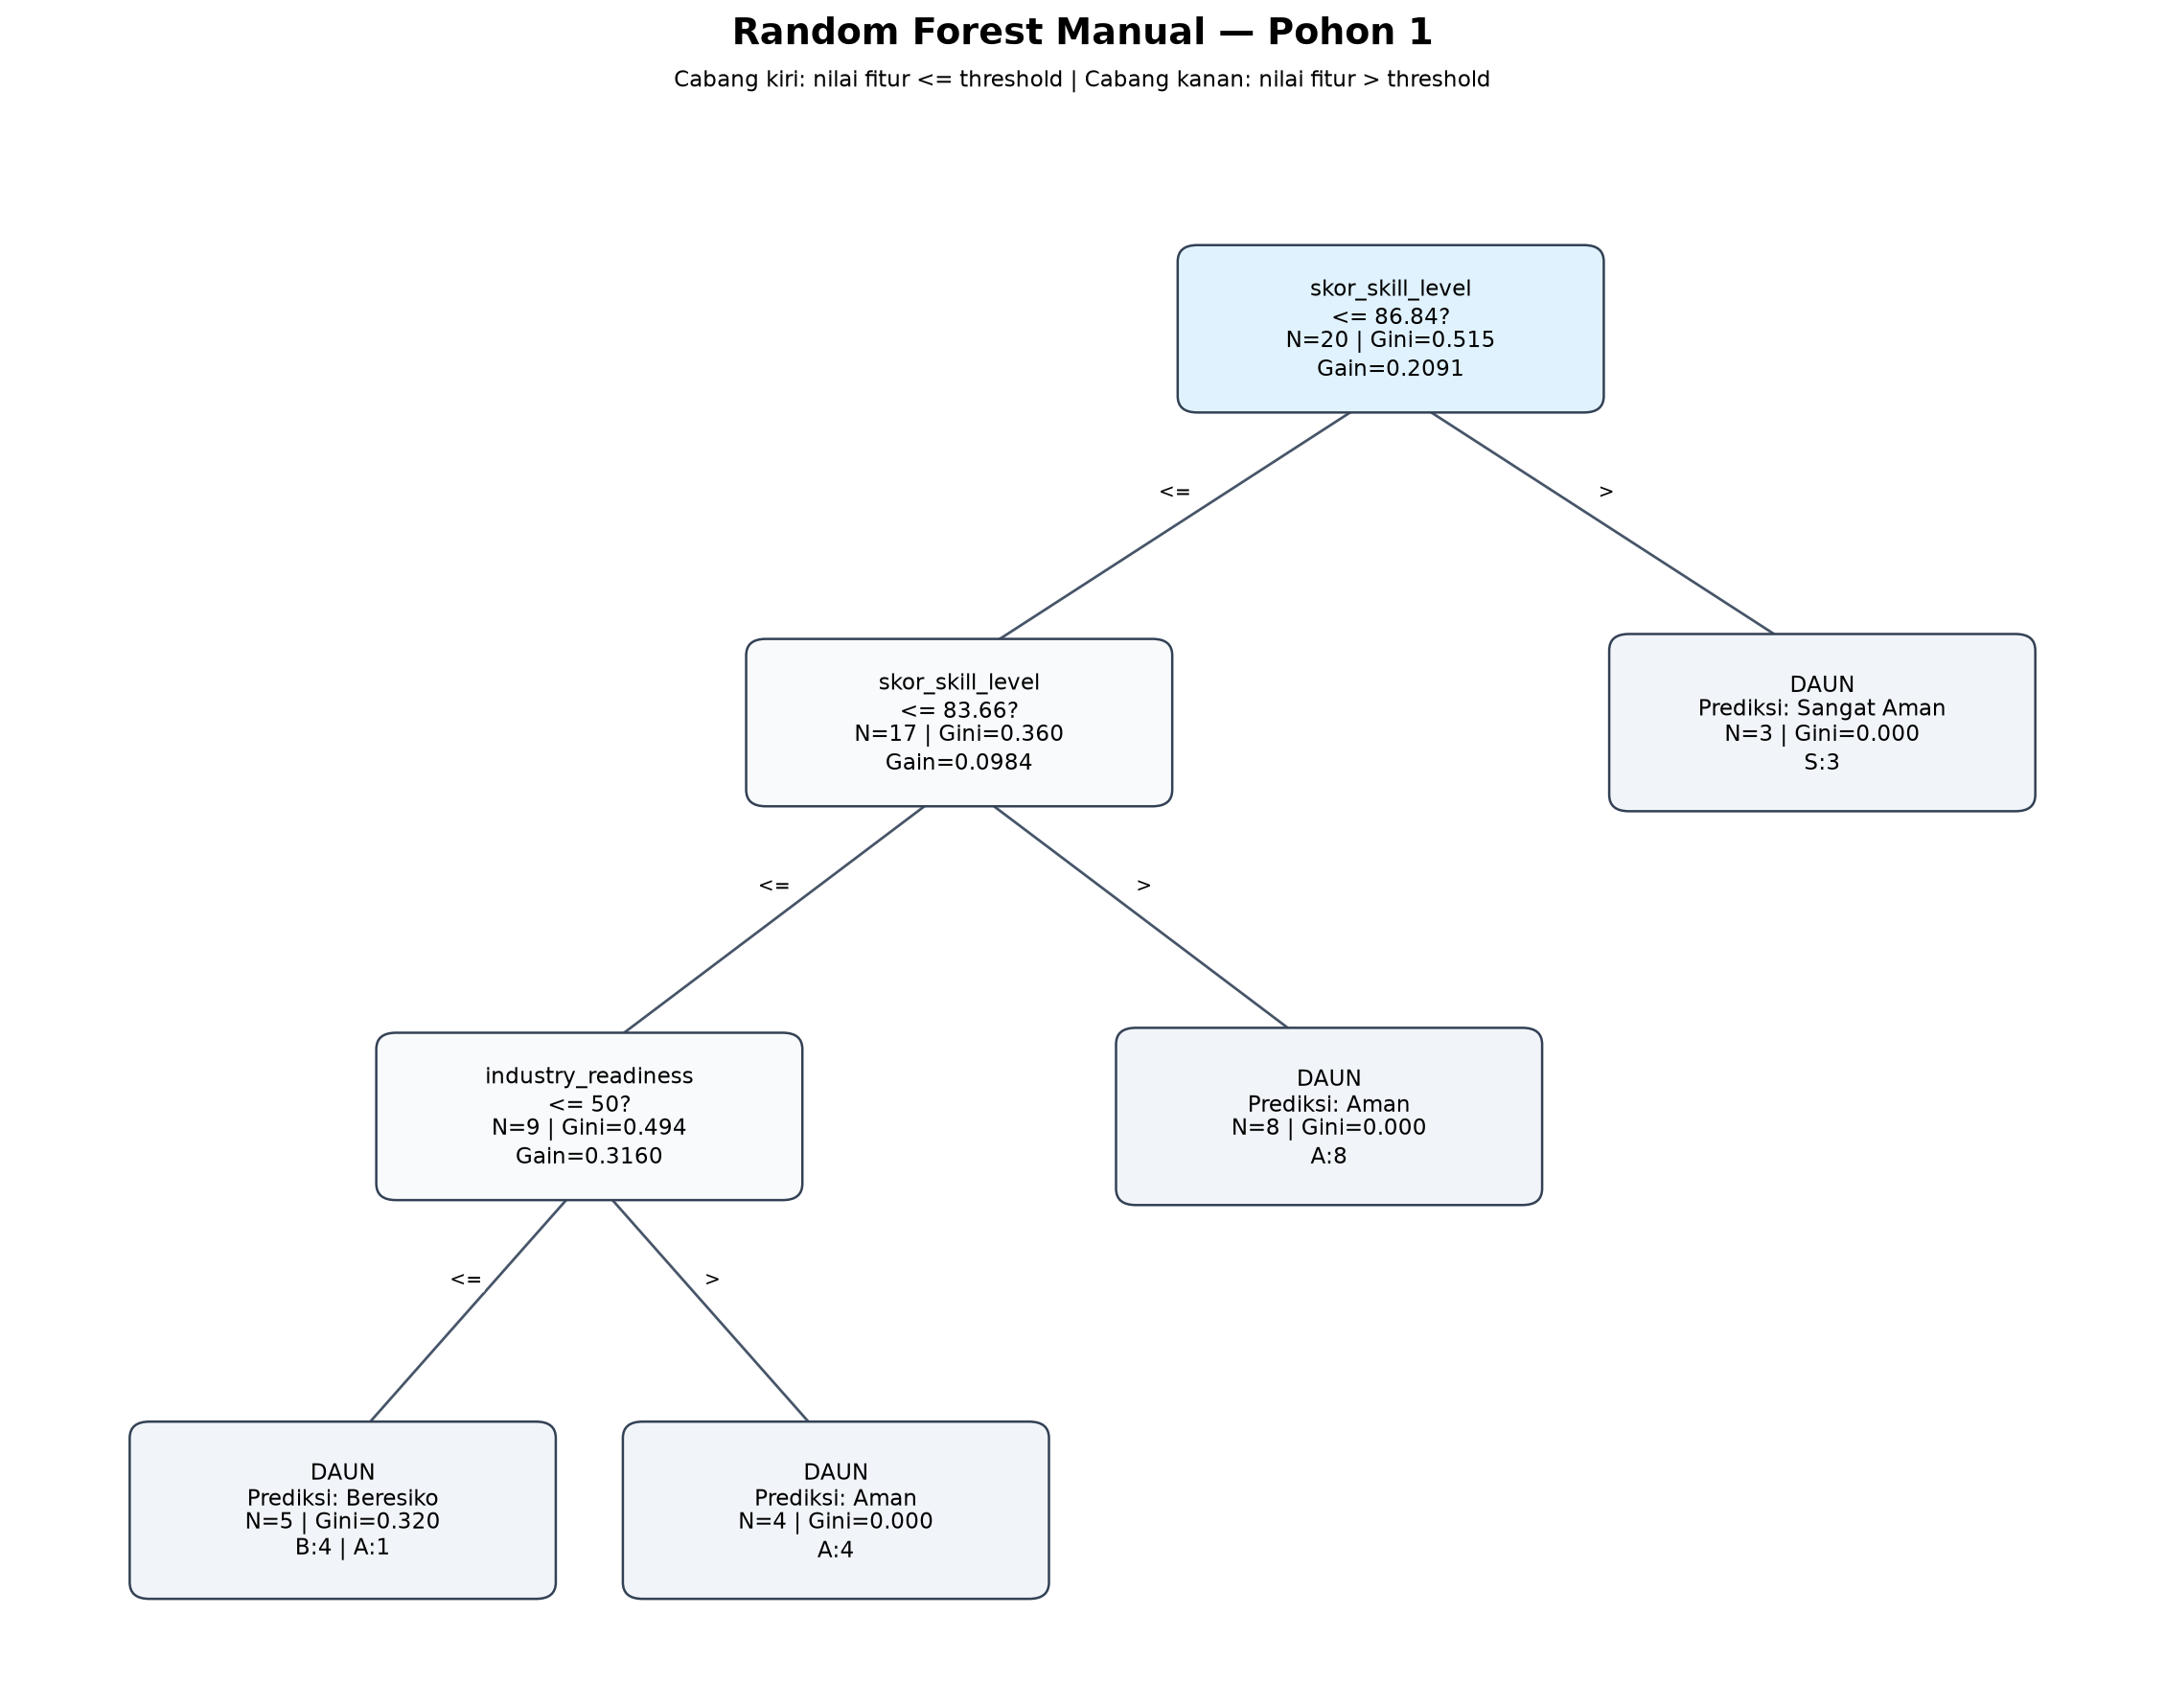

Pohon 2


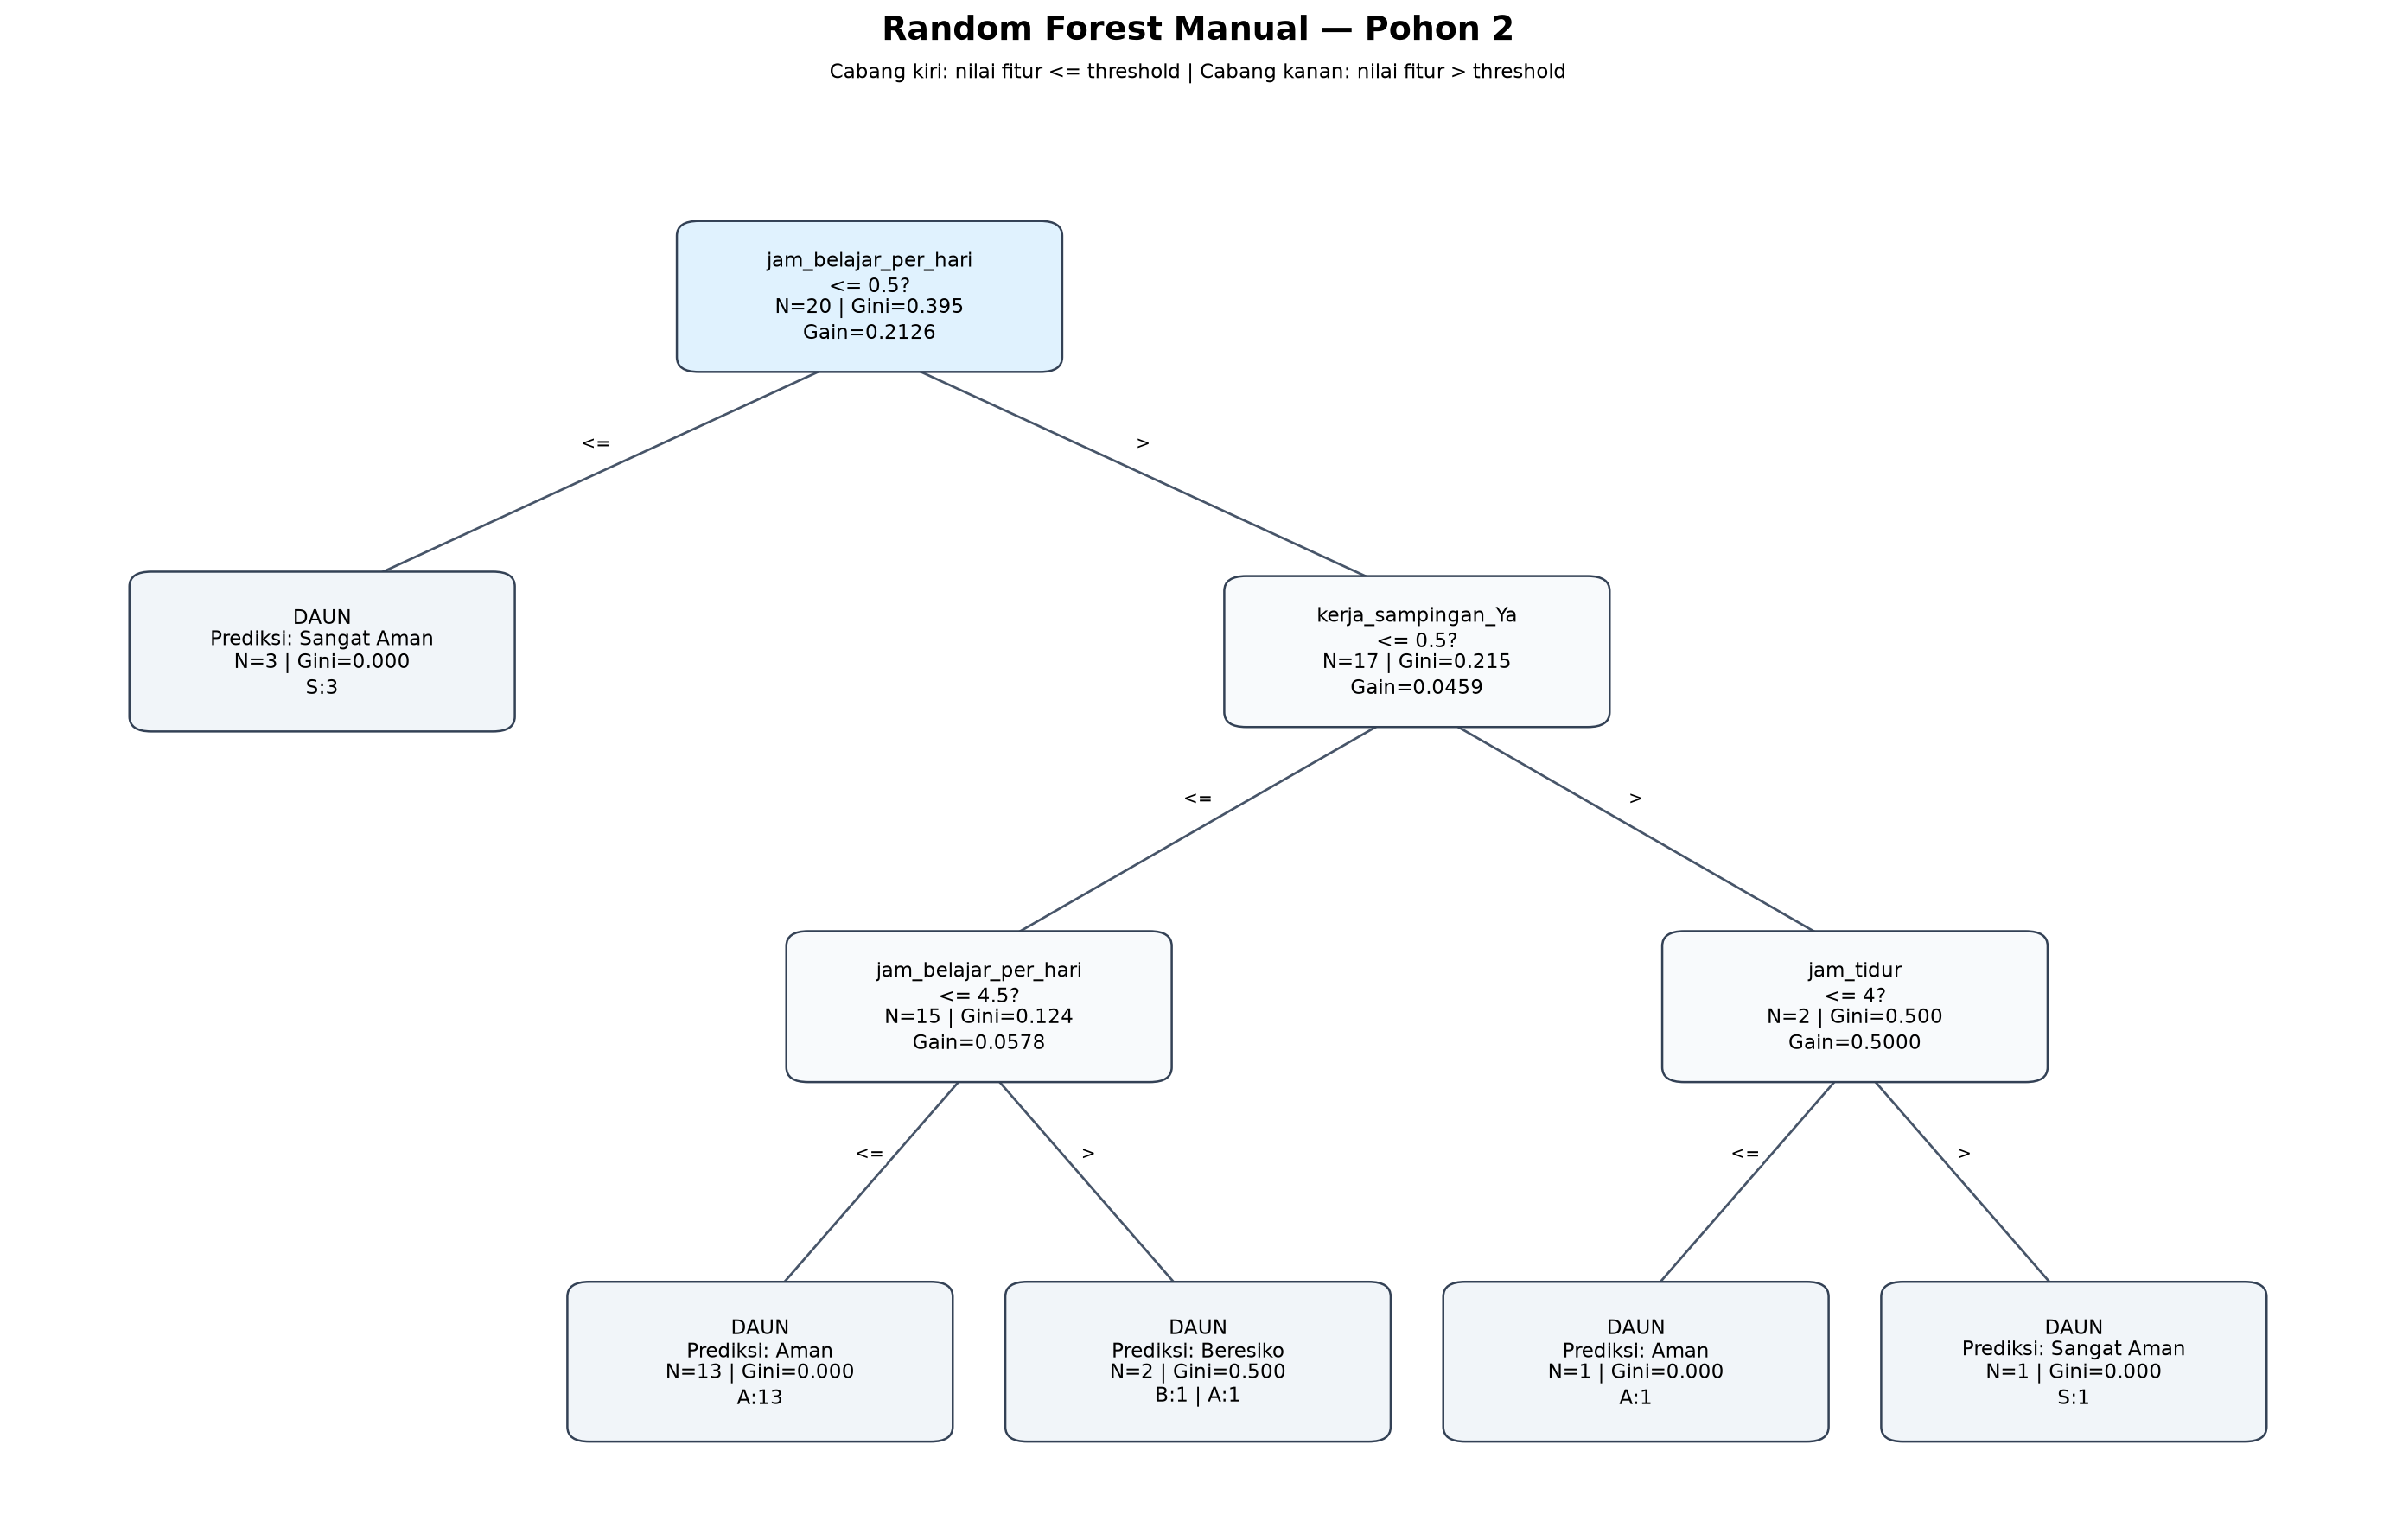

Pohon 3


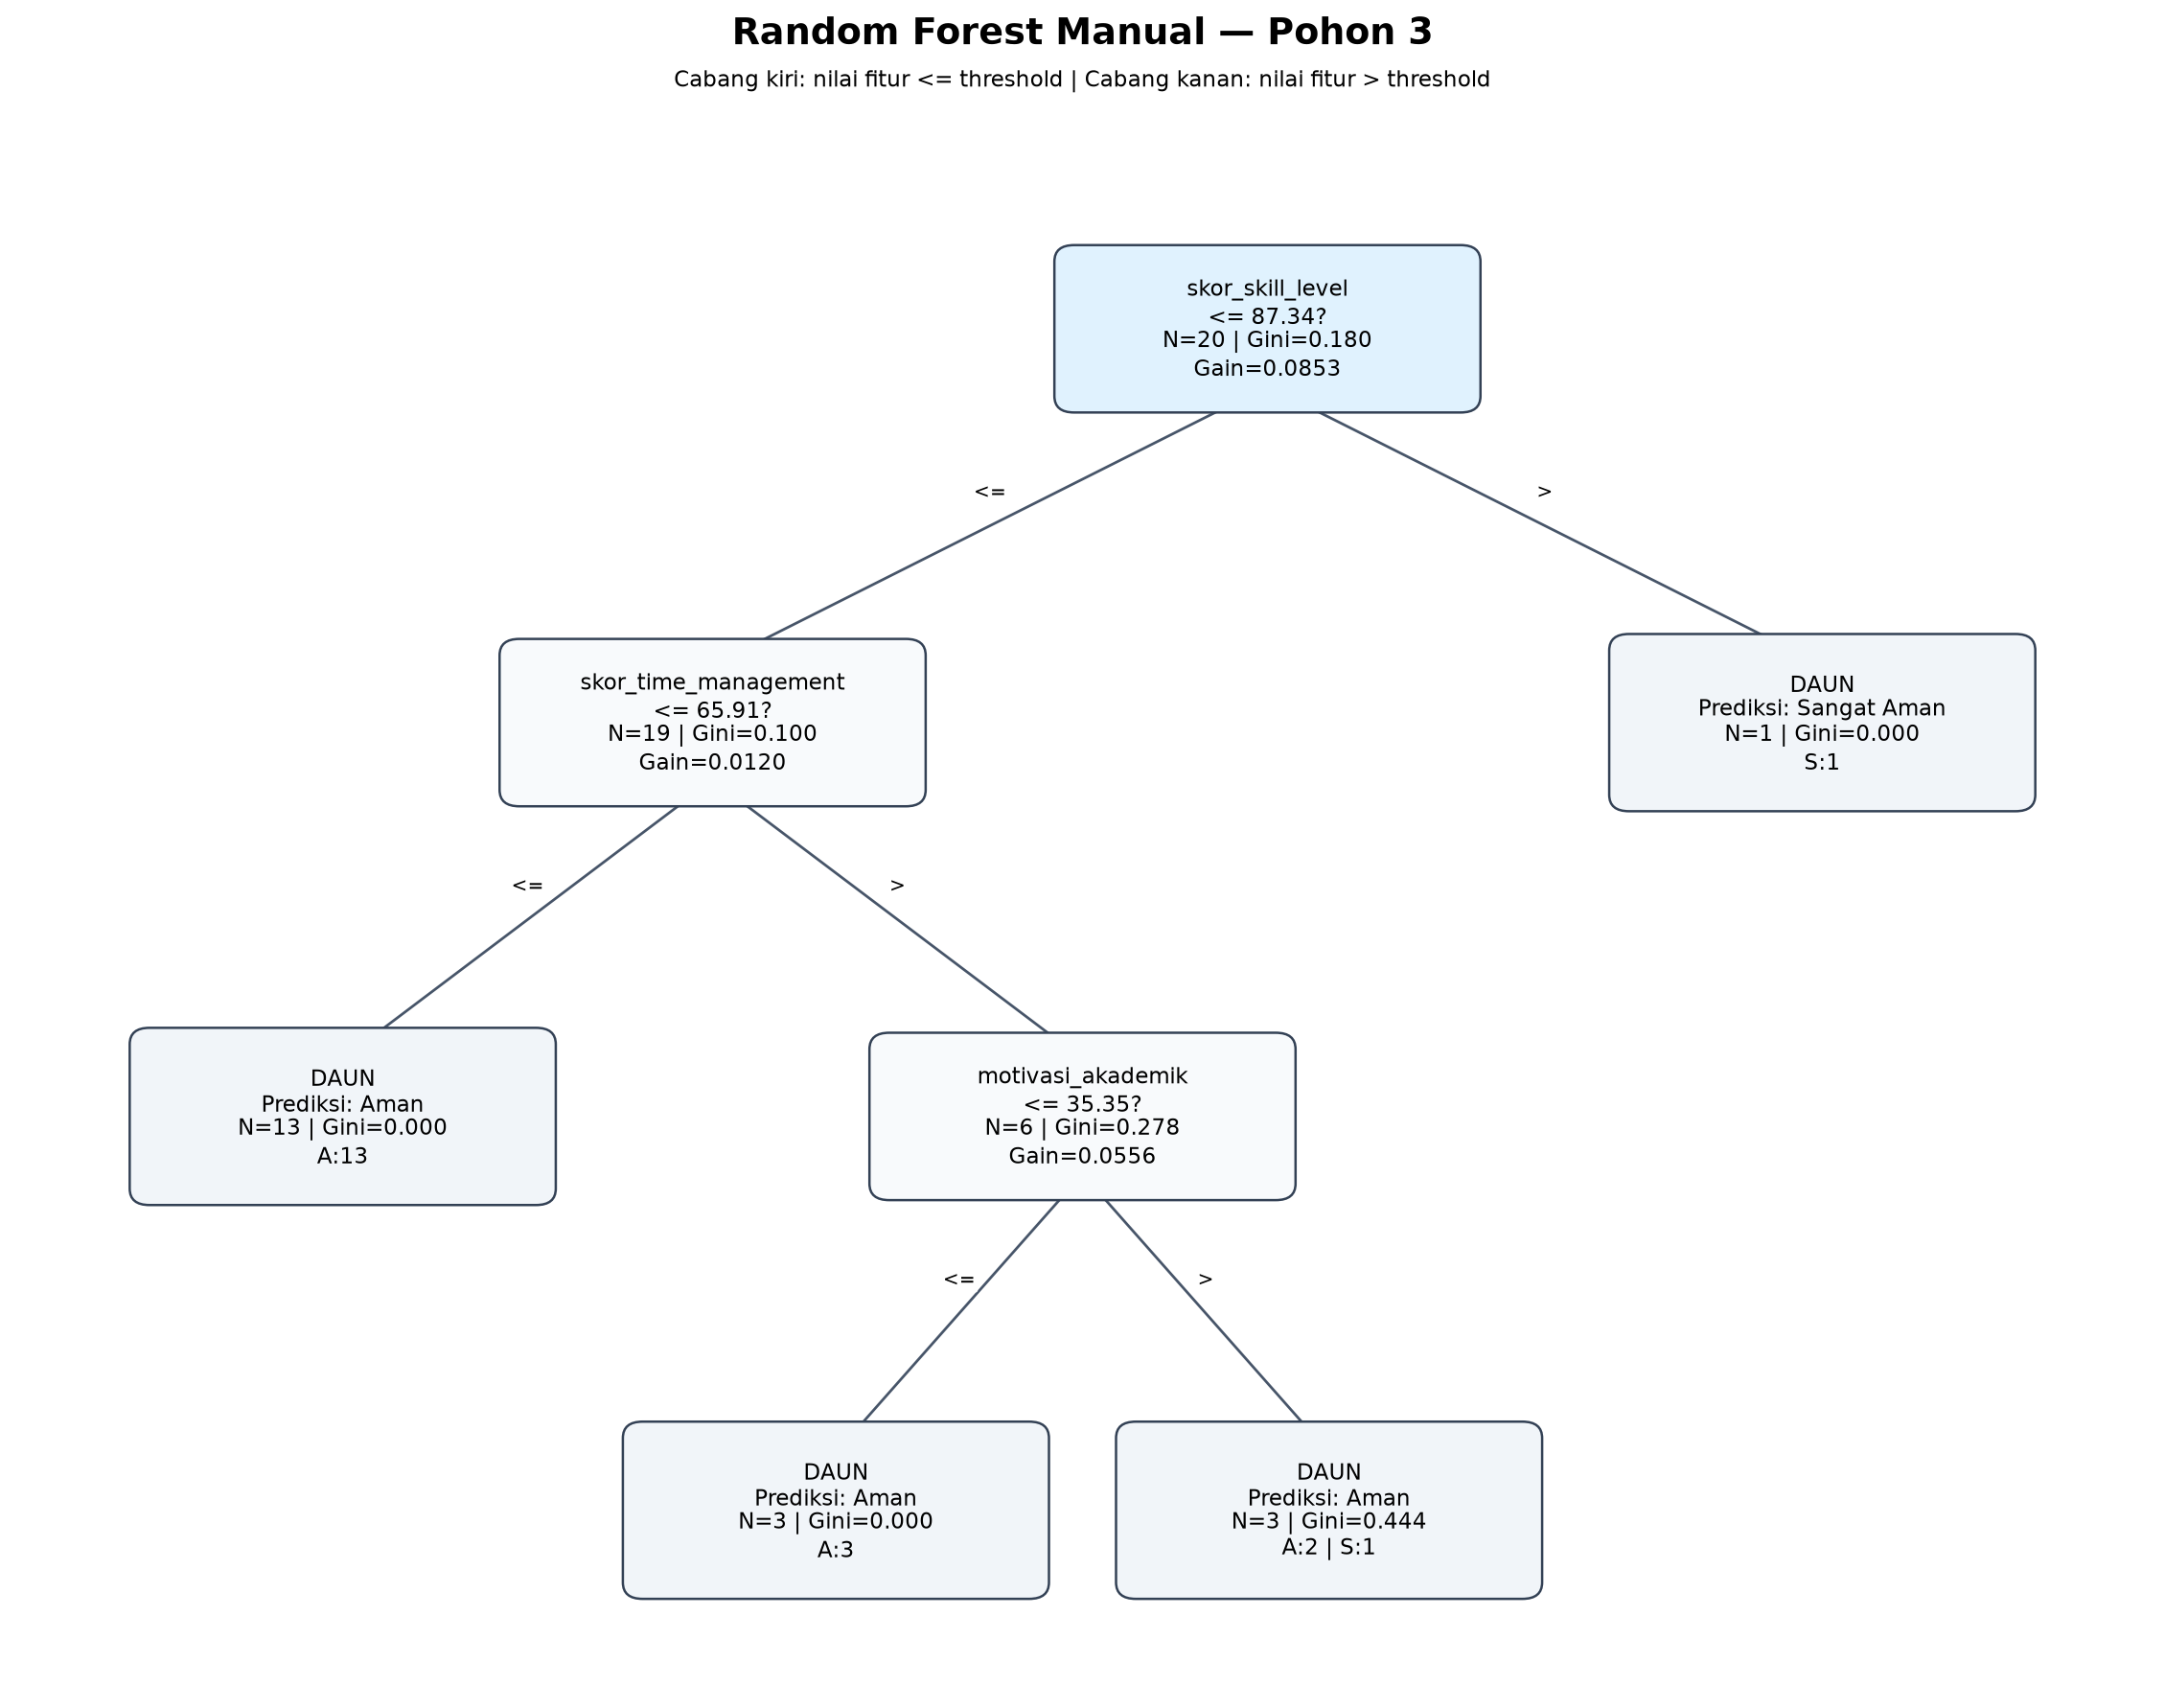

Pohon 4


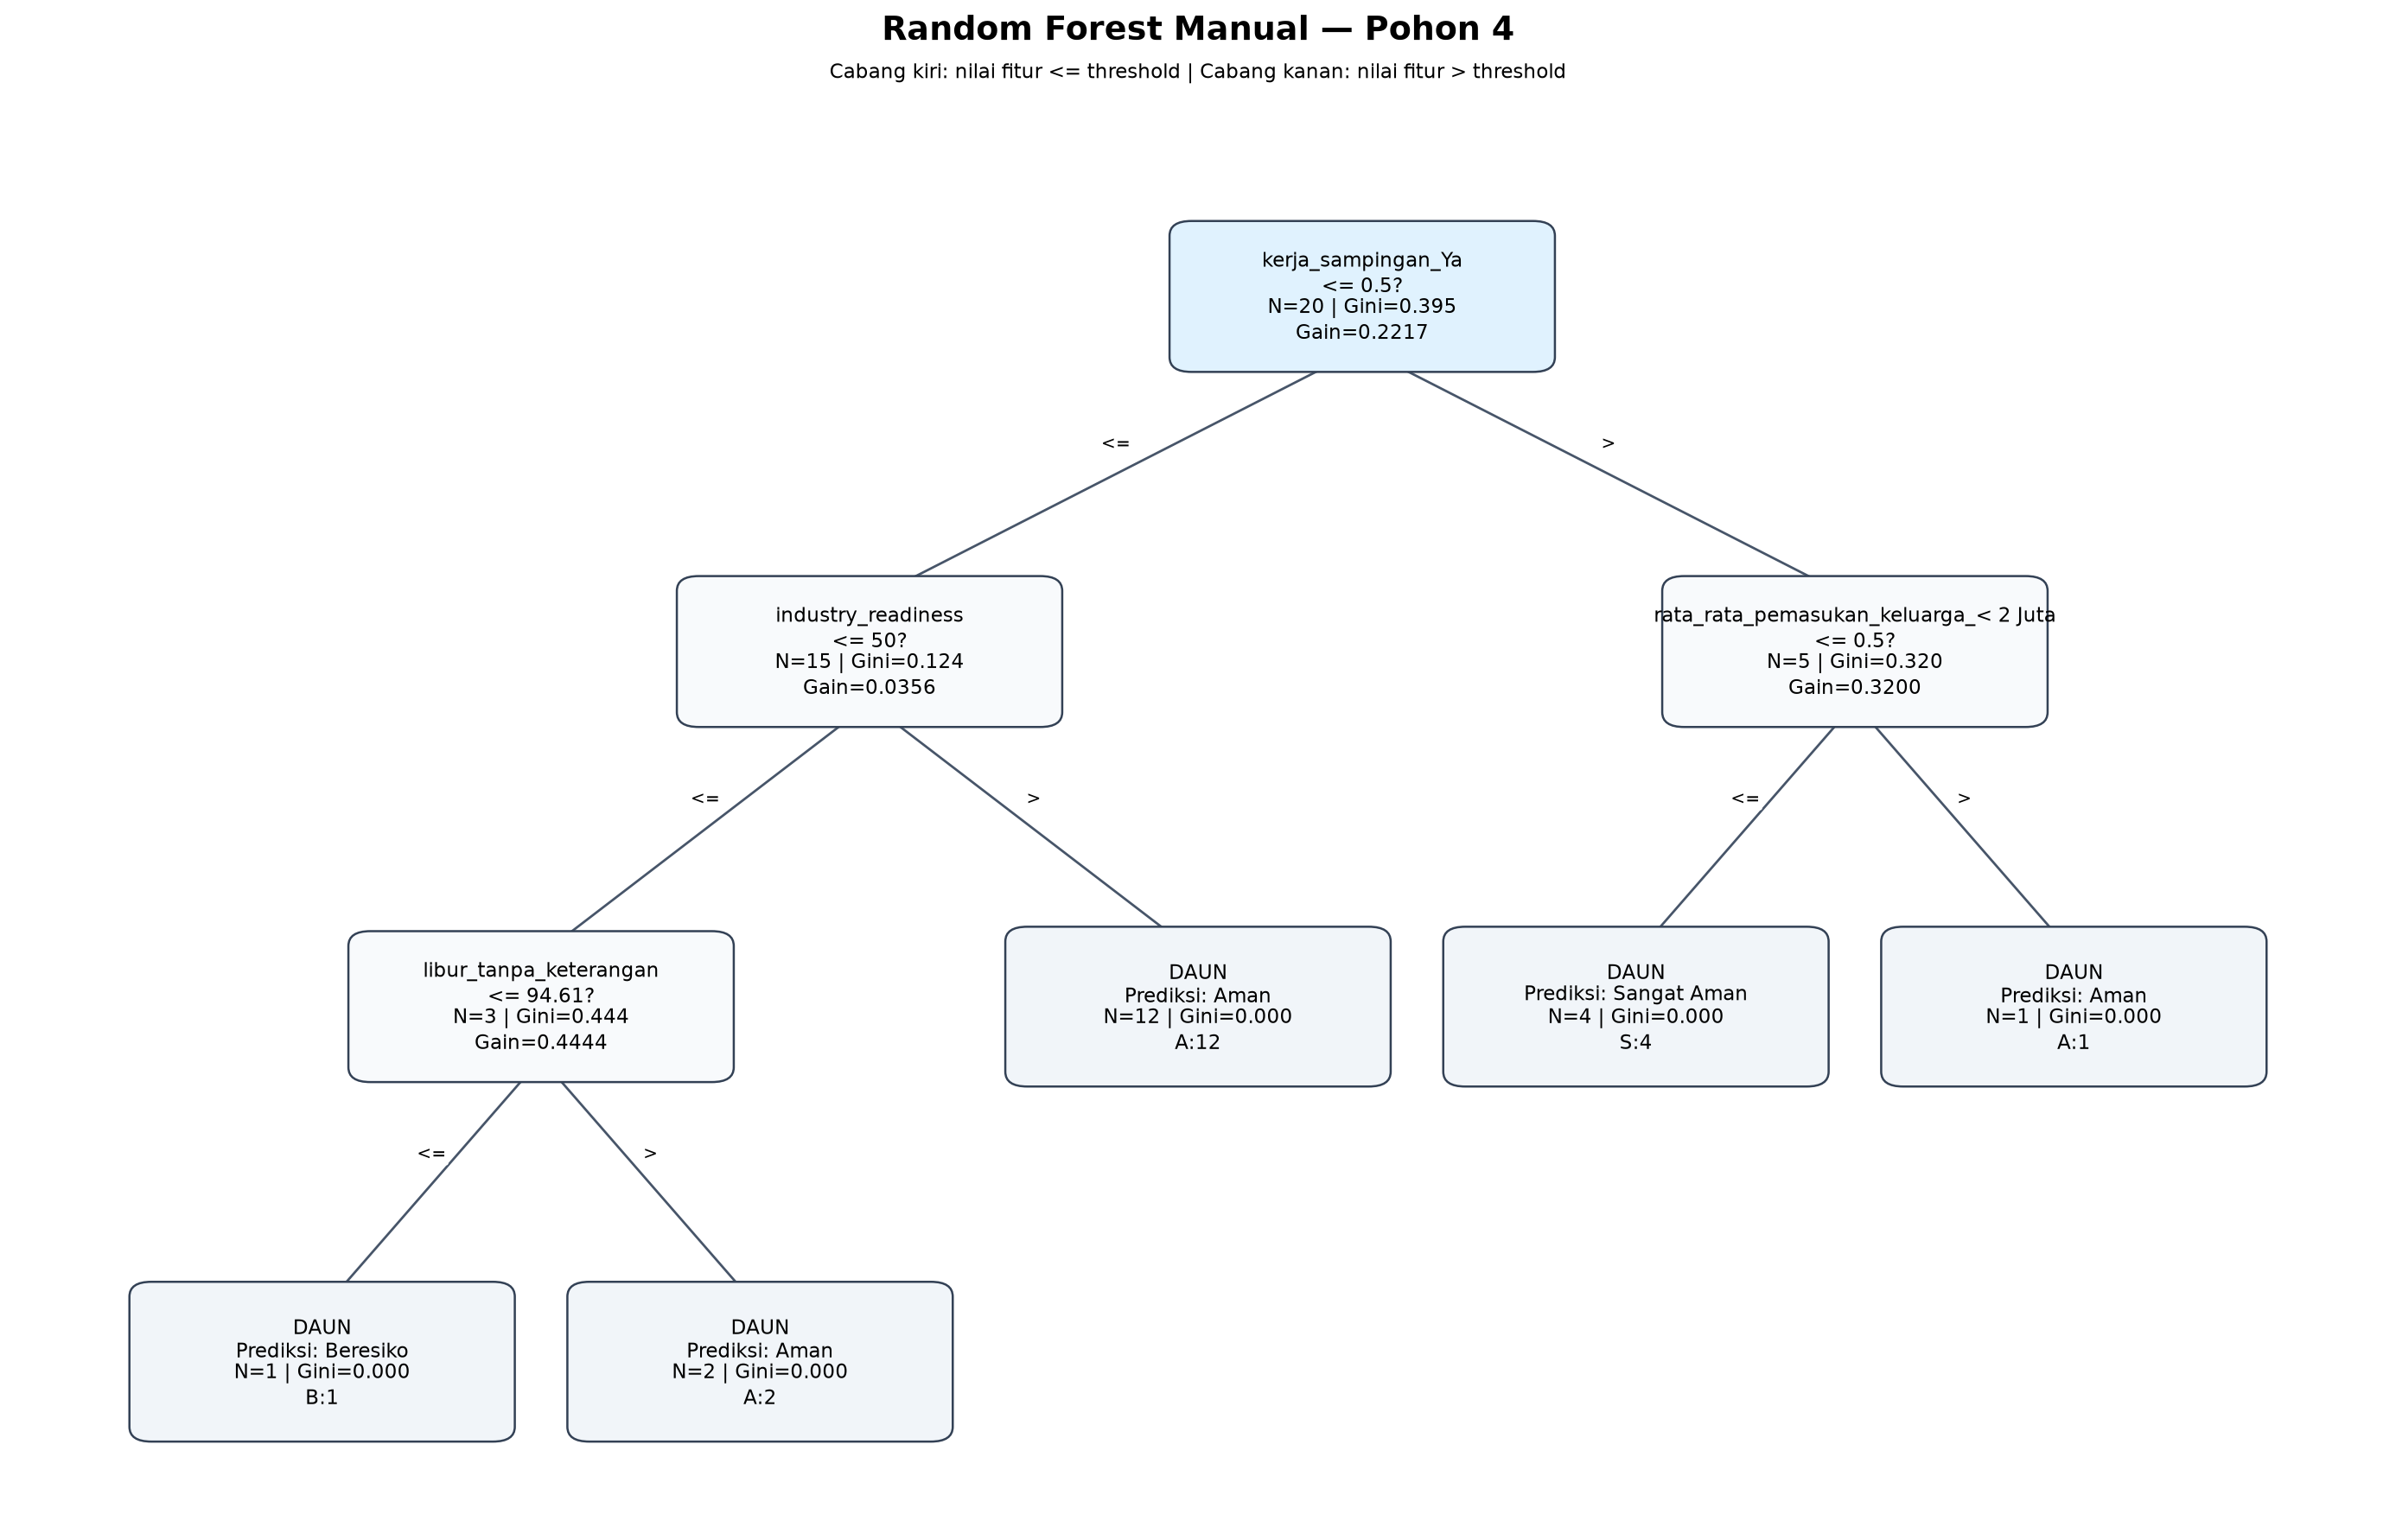

Pohon 5


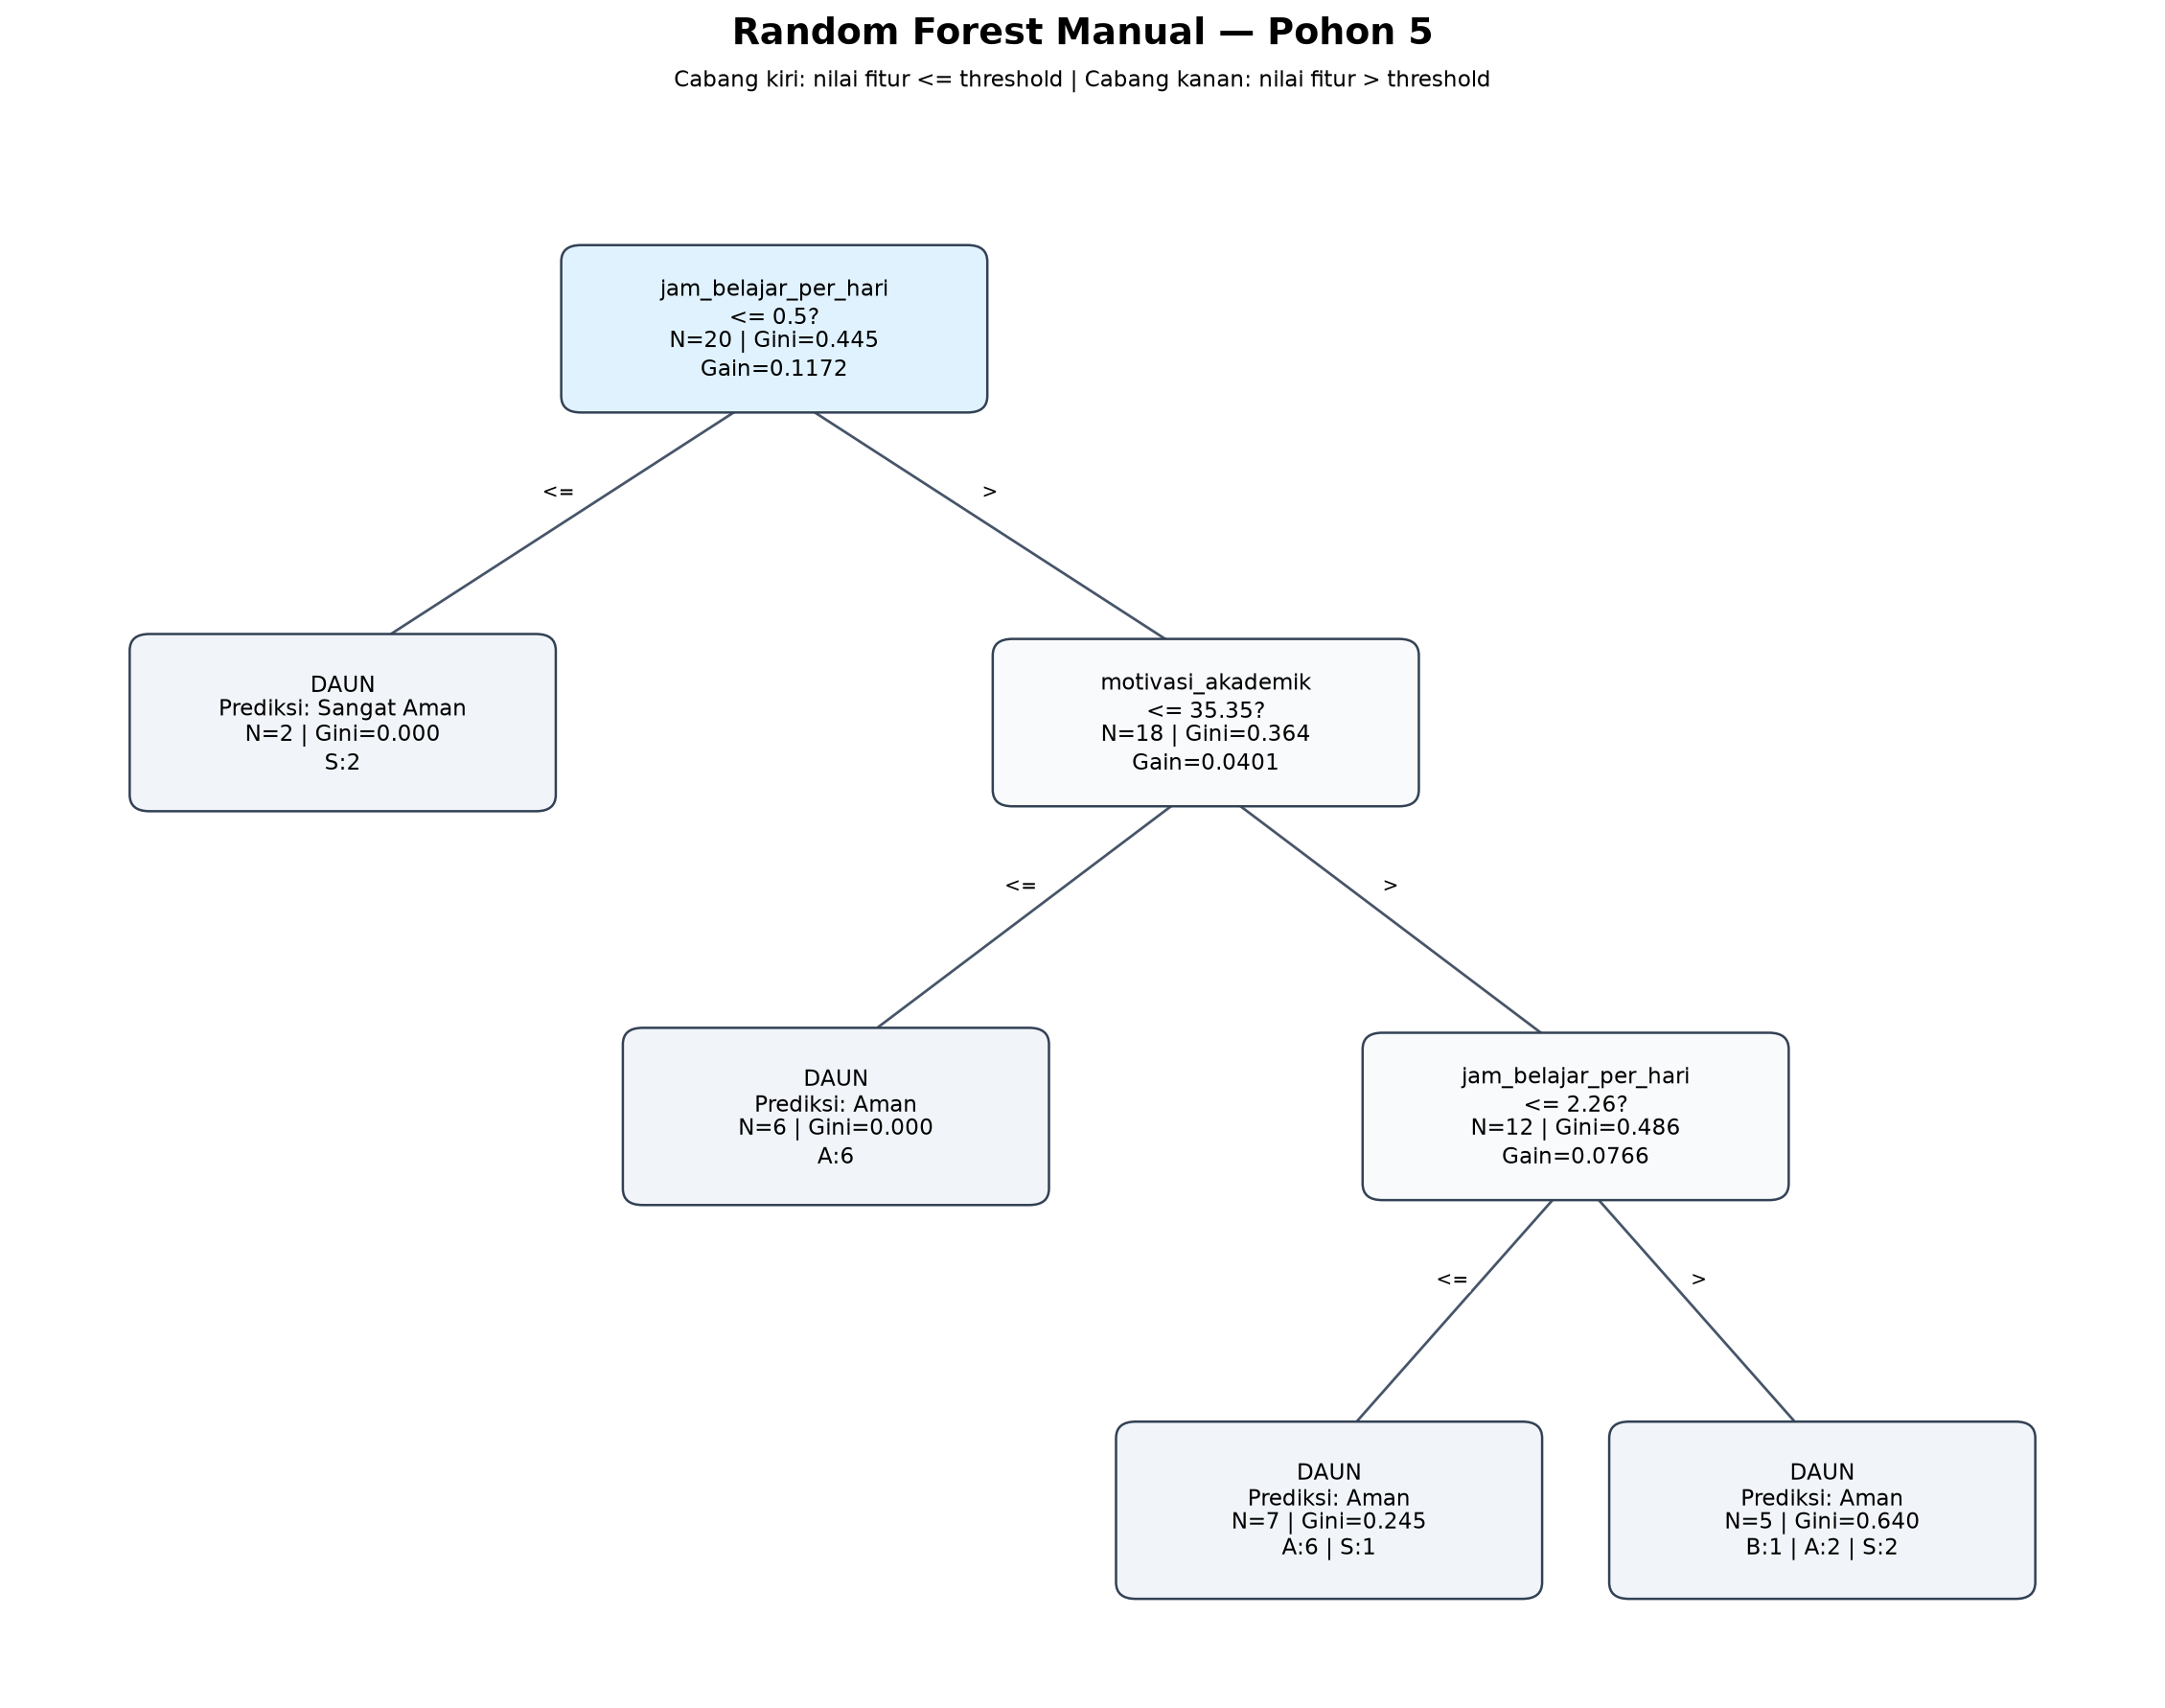

In [27]:
from IPython.display import Image

forest_image_paths = []
for tree_number, tree in enumerate(manual_forest, start=1):
    image_path = OUTPUT_DIR / f'pohon_random_forest_manual_{tree_number}.png'
    plot_decision_tree(tree, f'Random Forest Manual — Pohon {tree_number}', image_path)
    forest_image_paths.append(image_path)
    print(f'Pohon {tree_number}')
    display(Image(filename=str(image_path)))

### Aturan keputusan dari masing-masing pohon

Aturan dibentuk dengan menelusuri setiap jalur dari root sampai leaf. Setiap jalur menghasilkan kondisi IF–THEN dan satu kelas prediksi.

In [28]:
all_rules = []
for tree_number, tree in enumerate(manual_forest, start=1):
    rules = pd.DataFrame(tree_rules(tree))
    rules.insert(0, 'Pohon', tree_number)
    all_rules.append(rules)
    print(f'Aturan keputusan Pohon {tree_number}:')
    display(rules)
rules_forest = pd.concat(all_rules, ignore_index=True)
rules_forest.to_csv(OUTPUT_DIR/'aturan_keputusan_5_pohon.csv', index=False)

Aturan keputusan Pohon 1:


,Pohon,Aturan,Prediksi,Jumlah data node,Distribusi kelas,Gini daun
0,1,skor_skill_level <= 86.835 AND skor_skill_leve...,Beresiko,5,"{'Beresiko': 4, 'Aman': 1, 'Sangat Aman': 0}",0.320000
1,1,skor_skill_level <= 86.835 AND skor_skill_leve...,Aman,4,"{'Beresiko': 0, 'Aman': 4, 'Sangat Aman': 0}",0.000000
2,1,skor_skill_level <= 86.835 AND skor_skill_leve...,Aman,8,"{'Beresiko': 0, 'Aman': 8, 'Sangat Aman': 0}",0.000000
3,1,skor_skill_level > 86.835,Sangat Aman,3,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 3}",0.000000


Aturan keputusan Pohon 2:


,Pohon,Aturan,Prediksi,Jumlah data node,Distribusi kelas,Gini daun
0,2,jam_belajar_per_hari <= 0.5,Sangat Aman,3,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 3}",0.000000
1,2,jam_belajar_per_hari > 0.5 AND kerja_sampingan...,Aman,13,"{'Beresiko': 0, 'Aman': 13, 'Sangat Aman': 0}",0.000000
2,2,jam_belajar_per_hari > 0.5 AND kerja_sampingan...,Beresiko,2,"{'Beresiko': 1, 'Aman': 1, 'Sangat Aman': 0}",0.500000
3,2,jam_belajar_per_hari > 0.5 AND kerja_sampingan...,Aman,1,"{'Beresiko': 0, 'Aman': 1, 'Sangat Aman': 0}",0.000000
4,2,jam_belajar_per_hari > 0.5 AND kerja_sampingan...,Sangat Aman,1,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 1}",0.000000


Aturan keputusan Pohon 3:


,Pohon,Aturan,Prediksi,Jumlah data node,Distribusi kelas,Gini daun
0,3,skor_skill_level <= 87.335 AND skor_time_manag...,Aman,13,"{'Beresiko': 0, 'Aman': 13, 'Sangat Aman': 0}",0.000000
1,3,skor_skill_level <= 87.335 AND skor_time_manag...,Aman,3,"{'Beresiko': 0, 'Aman': 3, 'Sangat Aman': 0}",0.000000
2,3,skor_skill_level <= 87.335 AND skor_time_manag...,Aman,3,"{'Beresiko': 0, 'Aman': 2, 'Sangat Aman': 1}",0.444444
3,3,skor_skill_level > 87.335,Sangat Aman,1,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 1}",0.000000


Aturan keputusan Pohon 4:


,Pohon,Aturan,Prediksi,Jumlah data node,Distribusi kelas,Gini daun
0,4,kerja_sampingan_Ya <= 0.5 AND industry_readine...,Beresiko,1,"{'Beresiko': 1, 'Aman': 0, 'Sangat Aman': 0}",0.000000
1,4,kerja_sampingan_Ya <= 0.5 AND industry_readine...,Aman,2,"{'Beresiko': 0, 'Aman': 2, 'Sangat Aman': 0}",0.000000
2,4,kerja_sampingan_Ya <= 0.5 AND industry_readine...,Aman,12,"{'Beresiko': 0, 'Aman': 12, 'Sangat Aman': 0}",0.000000
3,4,kerja_sampingan_Ya > 0.5 AND rata_rata_pemasuk...,Sangat Aman,4,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 4}",0.000000
4,4,kerja_sampingan_Ya > 0.5 AND rata_rata_pemasuk...,Aman,1,"{'Beresiko': 0, 'Aman': 1, 'Sangat Aman': 0}",0.000000


Aturan keputusan Pohon 5:


,Pohon,Aturan,Prediksi,Jumlah data node,Distribusi kelas,Gini daun
0,5,jam_belajar_per_hari <= 0.5,Sangat Aman,2,"{'Beresiko': 0, 'Aman': 0, 'Sangat Aman': 2}",0.000000
1,5,jam_belajar_per_hari > 0.5 AND motivasi_akadem...,Aman,6,"{'Beresiko': 0, 'Aman': 6, 'Sangat Aman': 0}",0.000000
2,5,jam_belajar_per_hari > 0.5 AND motivasi_akadem...,Aman,7,"{'Beresiko': 0, 'Aman': 6, 'Sangat Aman': 1}",0.244898
3,5,jam_belajar_per_hari > 0.5 AND motivasi_akadem...,Aman,5,"{'Beresiko': 1, 'Aman': 2, 'Sangat Aman': 2}",0.640000


## 4.2.3.7 Pencocokan prediksi 20 sampel dengan majority voting

Setiap pohon memberikan satu prediksi pada setiap sampel. Kelas dengan suara terbanyak menjadi prediksi akhir Random Forest manual:

\[
\hat{y}=mode(T_1(x),T_2(x),T_3(x),T_4(x),T_5(x))
\]

Akurasi pencocokan dihitung sebagai jumlah prediksi benar dibagi jumlah sampel dikali 100%. Karena kelima pohon dibentuk dari 20 sampel yang sama melalui bootstrap, akurasi bagian ini adalah kecocokan demonstrasi pada sampel manual, bukan evaluasi hold-out independen.

In [29]:
vote_rows = []
forest_predictions = []
per_tree_predictions = []
for i in range(len(X_base)):
    row = X_base.iloc[i]
    votes = [predict_tree(tree, row) for tree in manual_forest]
    pred_final = majority_vote(votes)
    forest_predictions.append(pred_final)
    per_tree_predictions.append(votes)
    vote_rows.append({
        'No Sampel': i+1,
        'source_csv_line': int(sample.iloc[i]['source_csv_line']),
        'Aktual': y_base.iloc[i],
        **{f'Suara Pohon {j+1}': vote for j, vote in enumerate(votes)},
        'Hasil Majority Voting': pred_final,
        'Hasil': 'Benar' if pred_final == y_base.iloc[i] else 'Salah',
    })

vote_table = pd.DataFrame(vote_rows)
display(vote_table)
manual_correct = int((vote_table['Hasil'] == 'Benar').sum())
manual_accuracy = manual_correct / len(vote_table)
print(f'Prediksi benar = {manual_correct} dari {len(vote_table)} sampel')
print(f'Akurasi majority voting = {manual_correct}/{len(vote_table)} x 100% = {manual_accuracy*100:.2f}%')

cm_manual_forest = np.zeros((len(CLASS_ORDER), len(CLASS_ORDER)), dtype=int)
label_to_index = {label: idx for idx, label in enumerate(CLASS_ORDER)}
for actual, predicted in zip(y_base.astype(str), forest_predictions):
    cm_manual_forest[label_to_index[actual], label_to_index[predicted]] += 1
cm_manual_forest_df = pd.DataFrame(cm_manual_forest,
    index=[f'Aktual {c}' for c in CLASS_ORDER], columns=[f'Prediksi {c}' for c in CLASS_ORDER])
print('Confusion matrix — Random Forest manual 5 pohon:')
display(cm_manual_forest_df)

vote_table.to_csv(OUTPUT_DIR/'hasil_majority_voting_5_pohon.csv', index=False)
cm_manual_forest_df.to_csv(OUTPUT_DIR/'confusion_matrix_5_pohon.csv')

,No Sampel,source_csv_line,Aktual,Suara Pohon 1,Suara Pohon 2,Suara Pohon 3,Suara Pohon 4,Suara Pohon 5,Hasil Majority Voting,Hasil
0,1,163,Beresiko,Beresiko,Aman,Aman,Beresiko,Aman,Aman,Salah
1,2,114,Beresiko,Beresiko,Beresiko,Aman,Aman,Aman,Aman,Salah
2,3,3,Aman,Aman,Beresiko,Aman,Aman,Aman,Aman,Benar
3,4,10,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar
4,5,201,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar
5,6,85,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar
6,7,62,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar
7,8,80,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar
8,9,88,Aman,Beresiko,Aman,Aman,Aman,Aman,Aman,Benar
9,10,22,Aman,Aman,Aman,Aman,Aman,Aman,Aman,Benar


Prediksi benar = 17 dari 20 sampel
Akurasi majority voting = 17/20 x 100% = 85.00%
Confusion matrix — Random Forest manual 5 pohon:


,Prediksi Beresiko,Prediksi Aman,Prediksi Sangat Aman
Aktual Beresiko,0,2,0
Aktual Aman,0,14,0
Aktual Sangat Aman,0,1,3


## 4.2.3.8 Pencocokan dengan Random Forest final VOCAVISION

Tahap ini membandingkan prediksi mayoritas lima pohon manual dengan Random Forest final proyek pada **20 baris sumber yang sama**. Notebook akan mencari `data_clean.csv` di struktur folder proyek. Jika tidak ditemukan secara lokal, notebook mencoba mengambil file dari repository GitHub. Jika artefak model dan scaler final tersimpan di proyek, notebook akan memuatnya; jika tidak, model final direkonstruksi dari parameter training yang tercatat.

Konfigurasi pembanding mengikuti parameter final proyek yang tercatat: `n_estimators=100`, `max_depth=15`, `min_samples_split=10`, `min_samples_leaf=1`, `max_features='sqrt'`, `bootstrap=True`, `criterion='gini'`, `random_state=42`. Pipeline menggunakan pembagian train-test 80:20, StandardScaler, dan SMOTE pada data latih.

> Perlu dibedakan: akurasi hold-out model final mengukur data uji 20% dari dataset penuh. Perbandingan pada 20 sampel manual adalah pencocokan pada baris yang sengaja dipilih untuk ilustrasi; sebagian baris dapat berada pada data latih, sehingga hasil pada 20 sampel ini tidak boleh disebut akurasi hold-out independen.

Sumber dataset lokal: D:\Pribadi\my project web\VOCAVISION\backend\ml_model\data_clean.csv
Jumlah baris dataset lengkap: 253
P10 dataset penuh = 81.61; P80 dataset penuh = 85.66
Model final dimuat: D:\Pribadi\my project web\VOCAVISION\backend\ml_model\rf_classifier_best.pkl
Scaler final dimuat: D:\Pribadi\my project web\VOCAVISION\backend\ml_model\scaler.pkl
Akurasi hold-out model final = 86.27%
F1-macro hold-out model final = 0.7528


,No Sampel,source_csv_line,Bagian pada train-test split,Aktual,Prediksi RF Manual (5 Pohon),Prediksi RF Final (100 Pohon),Hasil RF Manual,Hasil RF Final,Kesamaan Prediksi
0,1,163,Data uji,Beresiko,Aman,Aman,Salah,Salah,Sama
1,2,114,Data uji,Beresiko,Aman,Aman,Salah,Salah,Sama
2,3,3,Data uji,Aman,Aman,Aman,Benar,Benar,Sama
3,4,10,Data latih,Aman,Aman,Aman,Benar,Benar,Sama
4,5,201,Data latih,Aman,Aman,Aman,Benar,Benar,Sama
5,6,85,Data latih,Aman,Aman,Aman,Benar,Benar,Sama
6,7,62,Data latih,Aman,Aman,Aman,Benar,Benar,Sama
7,8,80,Data uji,Aman,Aman,Aman,Benar,Benar,Sama
8,9,88,Data latih,Aman,Aman,Aman,Benar,Benar,Sama
9,10,22,Data latih,Aman,Aman,Aman,Benar,Benar,Sama


Confusion matrix — Random Forest Manual (5 Pohon):


,Prediksi Beresiko,Prediksi Aman,Prediksi Sangat Aman
Aktual Beresiko,0,2,0
Aktual Aman,0,14,0
Aktual Sangat Aman,0,1,3


Confusion matrix — Random Forest Final (100 Pohon):


,Prediksi Beresiko,Prediksi Aman,Prediksi Sangat Aman
Aktual Beresiko,0,2,0
Aktual Aman,0,14,0
Aktual Sangat Aman,0,1,3


Ringkasan perbandingan dua metode pada 20 sampel yang sama:


,Metode,Benar pada 20 sampel,Salah pada 20 sampel,Akurasi pencocokan 20 sampel (%),F1-macro 20 sampel
0,Random Forest Manual (5 Pohon),17,3,85.000000,0.586790
1,Random Forest Final (100 Pohon),17,3,85.000000,0.586790


Persentase kesamaan prediksi kedua metode = 90.00%


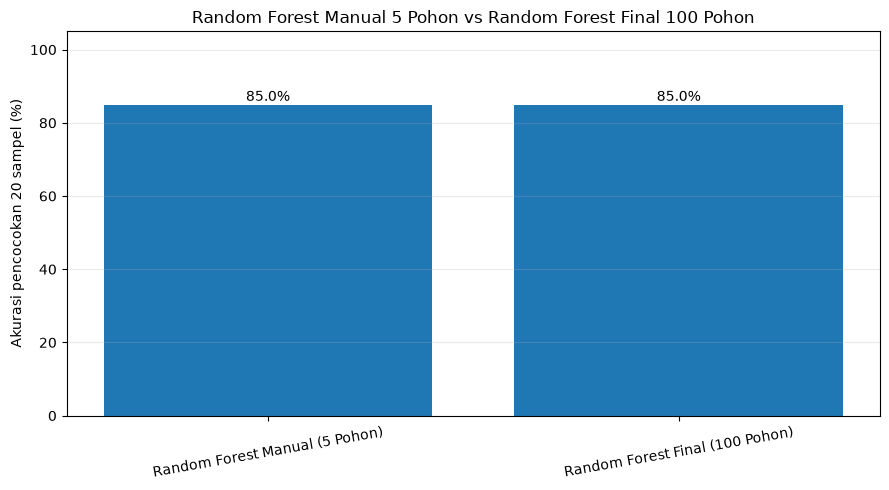

In [30]:
# Pembandingan model final bersifat opsional. Bagian manual di atas tidak membutuhkan dataset penuh.
comparison_ready = False
full_data_path = find_local_dataset()

if full_data_path is None:
    print('DATASET LENGKAP TIDAK DITEMUKAN DI DISK LOKAL.')
    print('Perhitungan manual lima pohon tetap selesai dan seluruh hasilnya tersimpan.')
    print('Letakkan data_clean.csv pada backend/ml_model/ atau isi DATA_CSV_PATH_OVERRIDE di sel persiapan.')
else:
    # Impor library training hanya ketika tahap pembandingan benar-benar bisa dijalankan.
    import joblib
    import json
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
    from imblearn.over_sampling import SMOTE
    import matplotlib.pyplot as plt

    df_full = pd.read_csv(full_data_path, dtype={'nisn': str}, low_memory=False)
    df_full = df_full.dropna(how='all').reset_index(drop=True)
    if 'nilai_rata_rata_raport' not in df_full.columns:
        raise KeyError('Kolom nilai_rata_rata_raport tidak ditemukan di data_clean.csv.')

    score_full = pd.to_numeric(df_full['nilai_rata_rata_raport'], errors='coerce')
    if score_full.isna().any():
        raise ValueError('Nilai rapor dataset lengkap mengandung missing/non-numeric values.')
    P10_FULL = float(np.percentile(score_full, 10))
    P80_FULL = float(np.percentile(score_full, 80))
    print('Sumber dataset lokal:', full_data_path)
    print('Jumlah baris dataset lengkap:', len(df_full))
    print(f'P10 dataset penuh = {P10_FULL:.2f}; P80 dataset penuh = {P80_FULL:.2f}')

    if not (np.isclose(P10_FULL, P10_FALLBACK, atol=0.02) and np.isclose(P80_FULL, P80_FALLBACK, atol=0.02)):
        raise ValueError('P10/P80 dari data_clean.csv berbeda dari ambang referensi sampel manual. Periksa versi dataset.')

    y_full = score_full.apply(lambda v: make_target(float(v), P10_FULL, P80_FULL)).astype(str)
    X_full = prepare_model_features(df_full)

    all_indices = np.arange(len(df_full))
    train_indices, test_indices = train_test_split(
        all_indices, test_size=0.20, random_state=42, stratify=y_full
    )

    # Prioritaskan artefak model/scaler yang sudah ada agar tidak melatih ulang setiap kali notebook dijalankan.
    model_candidates = [
        PROJECT_DIR / 'rf_classifier_best.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'rf_classifier_best.pkl',
        PROJECT_DIR / 'rf_model.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'rf_model.pkl',
    ]
    scaler_candidates = [
        PROJECT_DIR / 'scaler.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'scaler.pkl',
        PROJECT_DIR / 'scaler_final.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'scaler_final.pkl',
    ]
    feature_candidates = [
        PROJECT_DIR / 'train_columns.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'train_columns.pkl',
        PROJECT_DIR / 'feature_names.pkl',
        PROJECT_DIR / 'backend' / 'ml_model' / 'feature_names.pkl',
    ]

    # Cache lokal dipakai ulang hanya jika file CSV sumber belum berubah.
    cache_dir = OUTPUT_DIR / 'model_final_cache'
    cache_model_path = cache_dir / 'rf_final_local.joblib'
    cache_scaler_path = cache_dir / 'scaler_final_local.joblib'
    cache_features_path = cache_dir / 'feature_columns_local.joblib'
    cache_meta_path = cache_dir / 'cache_metadata.json'
    cache_valid = False
    if all(p.is_file() for p in [cache_model_path, cache_scaler_path, cache_features_path, cache_meta_path]):
        try:
            cache_meta = json.loads(cache_meta_path.read_text(encoding='utf-8'))
            current_stat = full_data_path.stat()
            cache_valid = (
                cache_meta.get('data_path') == str(full_data_path.resolve())
                and cache_meta.get('data_size') == current_stat.st_size
                and cache_meta.get('data_mtime_ns') == current_stat.st_mtime_ns
                and cache_meta.get('row_count') == len(df_full)
                and np.isclose(cache_meta.get('p10', np.nan), P10_FULL)
                and np.isclose(cache_meta.get('p80', np.nan), P80_FULL)
            )
        except (OSError, ValueError, TypeError, json.JSONDecodeError):
            cache_valid = False
    has_project_model_pair = (
        any(p.is_file() for p in model_candidates)
        and any(p.is_file() for p in scaler_candidates)
    )
    if cache_valid and not has_project_model_pair:
        model_candidates.append(cache_model_path)
        scaler_candidates.append(cache_scaler_path)
        feature_candidates.append(cache_features_path)
        print('Cache model lokal valid ditemukan; pelatihan ulang dilewati.')

    model_path = next((p for p in model_candidates if p.is_file()), None)
    scaler_path = next((p for p in scaler_candidates if p.is_file()), None)
    feature_path = next((p for p in feature_candidates if p.is_file()), None)

    model_loaded = model_path is not None and scaler_path is not None
    if model_loaded:
        model_final = joblib.load(model_path)
        scaler_final = joblib.load(scaler_path)
        model_feature_columns = joblib.load(feature_path) if feature_path is not None else list(X_full.columns)
        model_feature_columns = list(model_feature_columns)
        print('Model final dimuat:', model_path)
        print('Scaler final dimuat:', scaler_path)
    else:
        print('Artefak model/scaler belum tersedia; model final dibangun ulang dari dataset lokal.')
        model_feature_columns = list(X_full.columns)
        X_train_raw = X_full.iloc[train_indices].reindex(columns=model_feature_columns, fill_value=0)
        y_train = y_full.iloc[train_indices]

        scaler_final = StandardScaler()
        X_train_scaled = scaler_final.fit_transform(X_train_raw)
        smote_final = SMOTE(random_state=42)
        X_train_resampled, y_train_resampled = smote_final.fit_resample(X_train_scaled, y_train)

        # Jumlah worker dibatasi agar tidak menghabiskan semua core saat berjalan di komputer lokal.
        LOCAL_N_JOBS = max(1, min(4, (os.cpu_count() or 2) - 1))
        PARAMETER_FINAL = {
            'n_estimators': 100,
            'max_depth': 15,
            'min_samples_split': 10,
            'min_samples_leaf': 1,
            'max_features': 'sqrt',
            'bootstrap': True,
            'criterion': 'gini',
            'random_state': 42,
            'n_jobs': LOCAL_N_JOBS,
        }
        model_final = RandomForestClassifier(**PARAMETER_FINAL)
        model_final.fit(X_train_resampled, y_train_resampled)
        print(f'Model selesai dilatih menggunakan {LOCAL_N_JOBS} worker CPU.')

        # Simpan hasil rekonstruksi lokal agar eksekusi berikutnya tidak perlu melatih ulang.
        cache_dir.mkdir(parents=True, exist_ok=True)
        joblib.dump(model_final, cache_model_path)
        joblib.dump(scaler_final, cache_scaler_path)
        joblib.dump(model_feature_columns, cache_features_path)
        current_stat = full_data_path.stat()
        cache_meta_path.write_text(json.dumps({
            'data_path': str(full_data_path.resolve()),
            'data_size': current_stat.st_size,
            'data_mtime_ns': current_stat.st_mtime_ns,
            'row_count': len(df_full),
            'p10': P10_FULL,
            'p80': P80_FULL,
        }, indent=2), encoding='utf-8')
        print('Model/scaler hasil rekonstruksi disimpan ke cache lokal:', cache_dir)

    if hasattr(model_final, 'n_features_in_') and model_final.n_features_in_ != len(model_feature_columns):
        raise ValueError('Jumlah fitur model tersimpan tidak cocok dengan daftar fitur yang tersedia.')

    X_test_model = X_full.iloc[test_indices].reindex(columns=model_feature_columns, fill_value=0)
    y_test = y_full.iloc[test_indices]
    pred_test = model_final.predict(scaler_final.transform(X_test_model))
    holdout_accuracy = accuracy_score(y_test, pred_test)
    holdout_f1_macro = f1_score(y_test, pred_test, average='macro')
    print(f'Akurasi hold-out model final = {holdout_accuracy*100:.2f}%')
    print(f'F1-macro hold-out model final = {holdout_f1_macro:.4f}')

    # source_csv_line = nomor baris CSV dengan header sebagai baris pertama.
    source_indices = pd.to_numeric(sample['source_csv_line'], errors='raise').astype(int).to_numpy() - 2
    if source_indices.min() < 0 or source_indices.max() >= len(df_full):
        raise IndexError('source_csv_line pada sampel berada di luar data_clean.csv.')
    if not np.allclose(
        pd.to_numeric(sample['nilai_rata_rata_raport'], errors='raise').to_numpy(),
        score_full.iloc[source_indices].to_numpy(), atol=1e-8
    ):
        raise ValueError('source_csv_line tidak cocok dengan nilai rapor pada dataset lengkap.')

    X_manual_full = X_full.iloc[source_indices].reindex(columns=model_feature_columns, fill_value=0)
    pred_model_20 = model_final.predict(scaler_final.transform(X_manual_full)).astype(str).tolist()
    actual_20 = y_full.iloc[source_indices].astype(str).tolist()
    train_set = set(train_indices.tolist())
    split_part = ['Data latih' if int(idx) in train_set else 'Data uji' for idx in source_indices]

    comparison = pd.DataFrame({
        'No Sampel': np.arange(1, len(sample)+1),
        'source_csv_line': sample['source_csv_line'].astype(int),
        'Bagian pada train-test split': split_part,
        'Aktual': actual_20,
        'Prediksi RF Manual (5 Pohon)': forest_predictions,
        'Prediksi RF Final (100 Pohon)': pred_model_20,
    })
    comparison['Hasil RF Manual'] = np.where(comparison['Aktual'] == comparison['Prediksi RF Manual (5 Pohon)'], 'Benar', 'Salah')
    comparison['Hasil RF Final'] = np.where(comparison['Aktual'] == comparison['Prediksi RF Final (100 Pohon)'], 'Benar', 'Salah')
    comparison['Kesamaan Prediksi'] = np.where(comparison['Prediksi RF Manual (5 Pohon)'] == comparison['Prediksi RF Final (100 Pohon)'], 'Sama', 'Berbeda')
    display(comparison)

    summary_rows = []
    for method, pred in [
        ('Random Forest Manual (5 Pohon)', forest_predictions),
        ('Random Forest Final (100 Pohon)', pred_model_20),
    ]:
        summary_rows.append({
            'Metode': method,
            'Benar pada 20 sampel': int(np.sum(np.asarray(actual_20) == np.asarray(pred))),
            'Salah pada 20 sampel': int(np.sum(np.asarray(actual_20) != np.asarray(pred))),
            'Akurasi pencocokan 20 sampel (%)': accuracy_score(actual_20, pred)*100,
            'F1-macro 20 sampel': f1_score(actual_20, pred, average='macro'),
        })
        cm = confusion_matrix(actual_20, pred, labels=CLASS_ORDER)
        print(f'Confusion matrix — {method}:')
        display(pd.DataFrame(cm, index=[f'Aktual {c}' for c in CLASS_ORDER], columns=[f'Prediksi {c}' for c in CLASS_ORDER]))

    comparison_summary = pd.DataFrame(summary_rows)
    print('Ringkasan perbandingan dua metode pada 20 sampel yang sama:')
    display(comparison_summary)
    agreement = float(np.mean(np.asarray(forest_predictions) == np.asarray(pred_model_20)))
    print(f'Persentase kesamaan prediksi kedua metode = {agreement*100:.2f}%')

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(comparison_summary['Metode'], comparison_summary['Akurasi pencocokan 20 sampel (%)'])
    ax.set_ylim(0, 105)
    ax.set_ylabel('Akurasi pencocokan 20 sampel (%)')
    ax.set_title('Random Forest Manual 5 Pohon vs Random Forest Final 100 Pohon')
    ax.tick_params(axis='x', rotation=10)
    ax.grid(axis='y', alpha=0.25)
    for bar, value in zip(bars, comparison_summary['Akurasi pencocokan 20 sampel (%)']):
        ax.text(bar.get_x()+bar.get_width()/2, value+1, f'{value:.1f}%', ha='center')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    comparison.to_csv(OUTPUT_DIR/'perbandingan_5_pohon_vs_model_final_20_sampel.csv', index=False)
    comparison_summary.to_csv(OUTPUT_DIR/'ringkasan_perbandingan_5_pohon_vs_model_final.csv', index=False)
    comparison_ready = True

if not comparison_ready:
    print('Pembandingan model final belum dijalankan karena data_clean.csv lokal belum tersedia.')

## 5. Kesimpulan

Notebook lokal ini menyajikan pembentukan **Random Forest manual lima pohon** dengan urutan perhitungan yang disusun mengikuti bagian perhitungan manual pada PDF:

1. Menampilkan 20 sampel dan distribusi kelas.
2. Menghitung Gini Index awal.
3. Membentuk lima sampel bootstrap, masing-masing berukuran 20.
4. Menghitung Gini Index, Gini Split, dan Gini Gain untuk subset fitur acak pada setiap node.
5. Memilih node berdasarkan Gini Gain tertinggi, membentuk lima pohon, serta menyusun aturan keputusan.
6. Menggabungkan prediksi lima pohon melalui majority voting.
7. Membandingkan prediksi forest manual dengan prediksi Random Forest final pada 20 baris sumber yang sama, apabila dataset lengkap tersedia.

**Batas interpretasi:** lima pohon manual dibatasi pada kedalaman maksimum tiga agar perhitungannya mudah ditelusuri. Model final proyek memakai 100 pohon dan pipeline training tersendiri. Hasil majority voting lima pohon adalah demonstrasi mekanisme Random Forest, bukan pengganti metrik evaluasi hold-out model final.

Berkas tabel dan gambar keluaran disimpan ke folder `hasil_perhitungan_manual_vocavision_pdf`. Dataset lengkap untuk pembandingan harus tersedia di disk lokal; notebook tidak melakukan unduhan otomatis. Model final yang direkonstruksi disimpan di subfolder `model_final_cache` agar dapat digunakan kembali.